In [1]:
from pathlib import Path

PROJECT_ROOT = next(
    (base for parent in (Path.cwd(), *Path.cwd().parents)
     for base in (parent, parent / 'Notebook')
     if (base / 'data' / 'raw' / 'weatherHistory.csv').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter from the repository, Notebook, or notebooks directory.')
DATA_DIR = PROJECT_ROOT / 'data'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
METRICS_DIR = PROJECT_ROOT / 'reports' / 'metrics'
for directory in (DATA_DIR / 'processed', FIGURES_DIR, METRICS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(DATA_DIR / 'raw' / 'weatherHistory.csv')

In [3]:
df.sample(7)

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
73684,2014-01-06 04:00:00.000 +0100,Mostly Cloudy,rain,6.600000,5.966667,0.87,4.8622,140.0,13.7977,0.0,1015.87,Foggy starting in the morning continuing until...
82804,2015-07-02 07:00:00.000 +0200,Partly Cloudy,rain,20.938889,20.938889,0.73,8.1305,24.0,16.1000,0.0,1022.14,Partly cloudy throughout the day.
4046,2006-07-25 14:00:00.000 +0200,Partly Cloudy,rain,32.233333,32.816667,0.41,7.7441,4.0,10.3523,0.0,1016.52,Partly cloudy starting in the morning continui...
71142,2014-08-02 06:00:00.000 +0200,Partly Cloudy,rain,18.755556,18.755556,0.93,7.9695,320.0,15.6009,0.0,1011.32,Partly cloudy starting in the morning continui...
73848,2014-07-12 00:00:00.000 +0200,Overcast,rain,17.200000,17.200000,0.93,11.0607,291.0,5.2164,0.0,1003.08,Mostly cloudy throughout the day.
1339,2006-08-04 19:00:00.000 +0200,Partly Cloudy,rain,18.888889,18.888889,0.89,7.8407,338.0,11.2700,0.0,0.00,Mostly cloudy until night.
7836,2006-10-03 12:00:00.000 +0200,Mostly Cloudy,rain,24.977778,24.977778,0.47,26.5006,219.0,9.9820,0.0,1012.21,Partly cloudy until night.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


## Preciption has 517 missing value


In [5]:
df.isnull().sum()

Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64

In [6]:
from sklearn.impute import SimpleImputer
si=SimpleImputer(strategy='most_frequent')
df['Precip Type'] = si.fit_transform(df[['Precip Type']]).ravel()

In [7]:
df.isnull().sum()

Formatted Date              0
Summary                     0
Precip Type                 0
Temperature (C)             0
Apparent Temperature (C)    0
Humidity                    0
Wind Speed (km/h)           0
Wind Bearing (degrees)      0
Visibility (km)             0
Loud Cover                  0
Pressure (millibars)        0
Daily Summary               0
dtype: int64

In [8]:
df['Precip Type'].value_counts()

Precip Type
rain    85741
snow    10712
Name: count, dtype: int64

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               96453 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


## Formatted Date,Summary,Precription Type ,Daily Summary ->Object And Rest all are of Float type

In [10]:
df['Summary'].value_counts()

Summary
Partly Cloudy                          31733
Mostly Cloudy                          28094
Overcast                               16597
Clear                                  10890
Foggy                                   7148
Breezy and Overcast                      528
Breezy and Mostly Cloudy                 516
Breezy and Partly Cloudy                 386
Dry and Partly Cloudy                     86
Windy and Partly Cloudy                   67
Light Rain                                63
Breezy                                    54
Windy and Overcast                        45
Humid and Mostly Cloudy                   40
Drizzle                                   39
Breezy and Foggy                          35
Windy and Mostly Cloudy                   35
Dry                                       34
Humid and Partly Cloudy                   17
Dry and Mostly Cloudy                     14
Rain                                      10
Windy                                      8
Hu

In [11]:
vc = df['Summary'].value_counts()

total = vc.sum()
cum_freq = 0

for category, freq in vc.items():
    cum_freq += freq
    cum_percent = (cum_freq / total) * 100
    
    print(f"{category:30} | Freq: {freq:6} | CumFreq: {cum_freq:6} | Cum%: {cum_percent:.2f}")

Partly Cloudy                  | Freq:  31733 | CumFreq:  31733 | Cum%: 32.90
Mostly Cloudy                  | Freq:  28094 | CumFreq:  59827 | Cum%: 62.03
Overcast                       | Freq:  16597 | CumFreq:  76424 | Cum%: 79.23
Clear                          | Freq:  10890 | CumFreq:  87314 | Cum%: 90.52
Foggy                          | Freq:   7148 | CumFreq:  94462 | Cum%: 97.94
Breezy and Overcast            | Freq:    528 | CumFreq:  94990 | Cum%: 98.48
Breezy and Mostly Cloudy       | Freq:    516 | CumFreq:  95506 | Cum%: 99.02
Breezy and Partly Cloudy       | Freq:    386 | CumFreq:  95892 | Cum%: 99.42
Dry and Partly Cloudy          | Freq:     86 | CumFreq:  95978 | Cum%: 99.51
Windy and Partly Cloudy        | Freq:     67 | CumFreq:  96045 | Cum%: 99.58
Light Rain                     | Freq:     63 | CumFreq:  96108 | Cum%: 99.64
Breezy                         | Freq:     54 | CumFreq:  96162 | Cum%: 99.70
Windy and Overcast             | Freq:     45 | CumFreq:  96207 

##### Partly Cloudy                  | Freq:  31733 | CumFreq:  31733 | Cum%: 32.90
##### Mostly Cloudy                  | Freq:  28094 | CumFreq:  59827 | Cum%: 62.03
##### Overcast                       | Freq:  16597 | CumFreq:  76424 | Cum%: 79.23
##### Clear                          | Freq:  10890 | CumFreq:  87314 | Cum%: 90.52
##### Foggy                          | Freq:   7148 | CumFreq:  94462 | Cum%: 97.94
##### Breezy and Overcast            | Freq:    528 | CumFreq:  94990 | Cum%: 98.48
##### Breezy and Mostly Cloudy       | Freq:    516 | CumFreq:  95506 | Cum%: 99.02
##### About the 99% of the data are explained by these columns ...so i am Going  the rest of the columns ...

In [12]:
threshold = 0.01  # 1%

vc = df['Summary'].value_counts(normalize=True)

rare_categories = vc[vc < threshold].index

df['Summary'] = df['Summary'].replace(rare_categories, 'Other')

In [13]:
df['Summary'].value_counts()

Summary
Partly Cloudy    31733
Mostly Cloudy    28094
Overcast         16597
Clear            10890
Foggy             7148
Other             1991
Name: count, dtype: int64

In [14]:
df['Daily Summary'].value_counts()

Daily Summary
Mostly cloudy throughout the day.                                                 20085
Partly cloudy throughout the day.                                                  9981
Partly cloudy until night.                                                         6169
Partly cloudy starting in the morning.                                             5184
Foggy in the morning.                                                              4201
                                                                                  ...  
Drizzle until morning.                                                               24
Light rain overnight.                                                                24
Rain until morning.                                                                  24
Rain until afternoon.                                                                24
Foggy starting overnight continuing until morning and breezy in the afternoon.       23
Name: count, Lengt

In [15]:
vc = df['Daily Summary'].value_counts()

total = vc.sum()
cum_freq = 0

for category, freq in vc.items():
    cum_freq += freq
    cum_percent = (cum_freq / total) * 100
    
    print(f"{category:30} | Freq: {freq:6} | CumFreq: {cum_freq:6} | Cum%: {cum_percent:.2f}")

Mostly cloudy throughout the day. | Freq:  20085 | CumFreq:  20085 | Cum%: 20.82
Partly cloudy throughout the day. | Freq:   9981 | CumFreq:  30066 | Cum%: 31.17
Partly cloudy until night.     | Freq:   6169 | CumFreq:  36235 | Cum%: 37.57
Partly cloudy starting in the morning. | Freq:   5184 | CumFreq:  41419 | Cum%: 42.94
Foggy in the morning.          | Freq:   4201 | CumFreq:  45620 | Cum%: 47.30
Foggy starting overnight continuing until morning. | Freq:   3576 | CumFreq:  49196 | Cum%: 51.01
Partly cloudy until evening.   | Freq:   3288 | CumFreq:  52484 | Cum%: 54.41
Mostly cloudy until night.     | Freq:   3095 | CumFreq:  55579 | Cum%: 57.62
Overcast throughout the day.   | Freq:   2952 | CumFreq:  58531 | Cum%: 60.68
Partly cloudy starting in the morning continuing until evening. | Freq:   2806 | CumFreq:  61337 | Cum%: 63.59
Foggy until morning.           | Freq:   2691 | CumFreq:  64028 | Cum%: 66.38
Partly cloudy starting in the morning continuing until night. | Freq:   213

### Daily Summary has a lots of Different values.....which will be the bad for the One Hot Encoding as well as since every columns has a seperate valuess so our model got overfit for everyvalue

### So it will be better to Replace it like...Is Morning | Is Evening | like that.....or even i can drop it since the same info are also provided Summary

In [16]:
df['is_morning'] = df['Daily Summary'].str.contains('morning', case=False, na=False).astype(int)
df['is_night'] = df['Daily Summary'].str.contains('night', case=False, na=False).astype(int)
df['is_evening'] = df['Daily Summary'].str.contains('evening', case=False, na=False).astype(int)
df['is_day'] = df['Daily Summary'].str.contains('throughout the day|day', case=False, na=False).astype(int)

In [17]:
df.head()

,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary,is_morning,is_night,is_evening,is_day
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.,0,0,0,1
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.,0,0,0,1
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.,0,0,0,1
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.,0,0,0,1
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.,0,0,0,1


### Since the date are not in int type...so let them first convert into the Date format.....and then into the Month ,Year and Days as the Weather are mostly related to the Season (Month)

In [18]:
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'], utc=True)
df['Formatted Date'] = df['Formatted Date'].dt.tz_convert(None)

df['year'] = df['Formatted Date'].dt.year
df['month'] = df['Formatted Date'].dt.month
df['day'] = df['Formatted Date'].dt.day
df['hour'] = df['Formatted Date'].dt.hour
df['day_of_week'] = df['Formatted Date'].dt.dayofweek

# df.drop(columns=['Formatted Date'], inplace=True)


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Formatted Date            96453 non-null  datetime64[ns]
 1   Summary                   96453 non-null  object        
 2   Precip Type               96453 non-null  object        
 3   Temperature (C)           96453 non-null  float64       
 4   Apparent Temperature (C)  96453 non-null  float64       
 5   Humidity                  96453 non-null  float64       
 6   Wind Speed (km/h)         96453 non-null  float64       
 7   Wind Bearing (degrees)    96453 non-null  float64       
 8   Visibility (km)           96453 non-null  float64       
 9   Loud Cover                96453 non-null  float64       
 10  Pressure (millibars)      96453 non-null  float64       
 11  Daily Summary             96453 non-null  object        
 12  is_morning        

In [20]:
for col in df.columns:
    print(f"{col} --> {df[col].nunique()} unique values")
    

Formatted Date --> 96429 unique values
Summary --> 6 unique values
Precip Type --> 2 unique values
Temperature (C) --> 7574 unique values
Apparent Temperature (C) --> 8984 unique values
Humidity --> 90 unique values
Wind Speed (km/h) --> 2484 unique values
Wind Bearing (degrees) --> 360 unique values
Visibility (km) --> 949 unique values
Loud Cover --> 1 unique values
Pressure (millibars) --> 4979 unique values
Daily Summary --> 214 unique values
is_morning --> 2 unique values
is_night --> 2 unique values
is_evening --> 2 unique values
is_day --> 2 unique values
year --> 12 unique values
month --> 12 unique values
day --> 31 unique values
hour --> 24 unique values
day_of_week --> 7 unique values


In [21]:
df.isnull().sum()

Formatted Date              0
Summary                     0
Precip Type                 0
Temperature (C)             0
Apparent Temperature (C)    0
Humidity                    0
Wind Speed (km/h)           0
Wind Bearing (degrees)      0
Visibility (km)             0
Loud Cover                  0
Pressure (millibars)        0
Daily Summary               0
is_morning                  0
is_night                    0
is_evening                  0
is_day                      0
year                        0
month                       0
day                         0
hour                        0
day_of_week                 0
dtype: int64

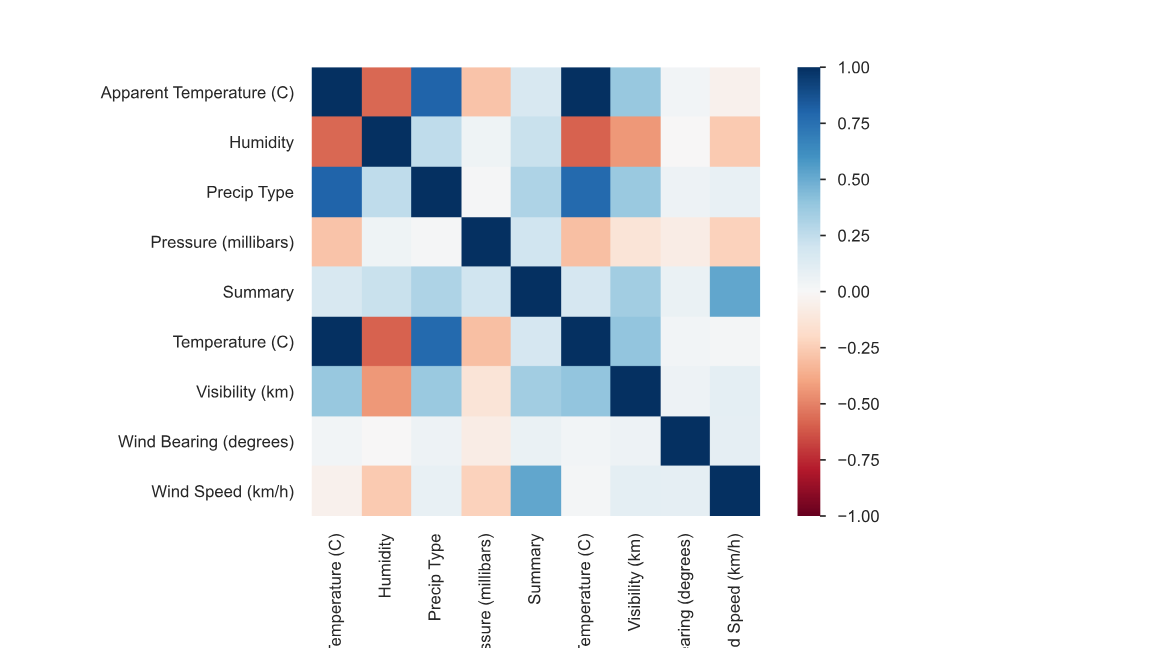

### Apparant Temp are highly corelated with -> Precipitation Type , Temperature , Visibility (about 70%)
### Summary -> Wind Speed
### Visibility -> Precipitation Type
### *Humidity And Temps are highly negative Corelated*

### Since The Apparant Temp and Temperature are almost similar so ...remove one......I am removing the Apparent Temperatue

In [22]:
df = df.drop(columns=['Apparent Temperature (C)'])

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Formatted Date          96453 non-null  datetime64[ns]
 1   Summary                 96453 non-null  object        
 2   Precip Type             96453 non-null  object        
 3   Temperature (C)         96453 non-null  float64       
 4   Humidity                96453 non-null  float64       
 5   Wind Speed (km/h)       96453 non-null  float64       
 6   Wind Bearing (degrees)  96453 non-null  float64       
 7   Visibility (km)         96453 non-null  float64       
 8   Loud Cover              96453 non-null  float64       
 9   Pressure (millibars)    96453 non-null  float64       
 10  Daily Summary           96453 non-null  object        
 11  is_morning              96453 non-null  int64         
 12  is_night                96453 non-null  int64 

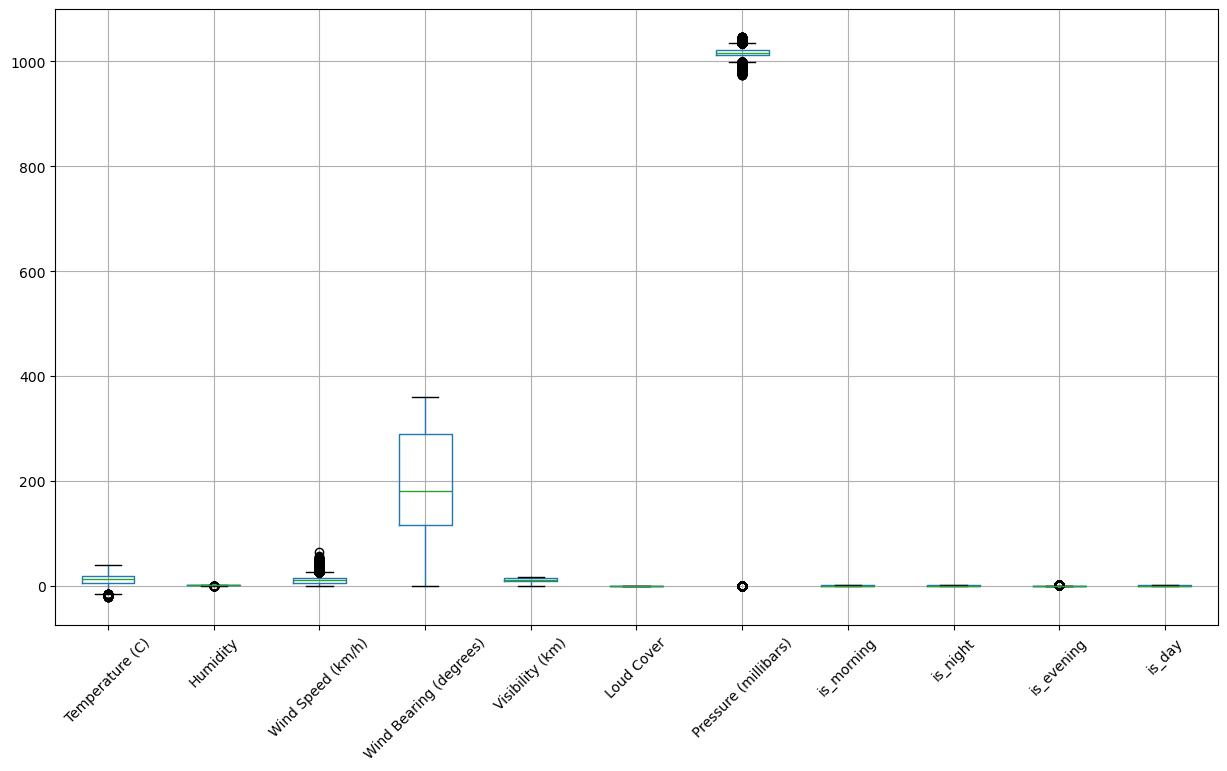

In [24]:
import matplotlib.pyplot as plt

df.select_dtypes(include=['float64','int64']).boxplot(figsize=(15,8))
plt.xticks(rotation=45)
plt.show()

### BoxPlot of Binary columns like is Evening ...did not works....and also not need to study...since it is feature column....

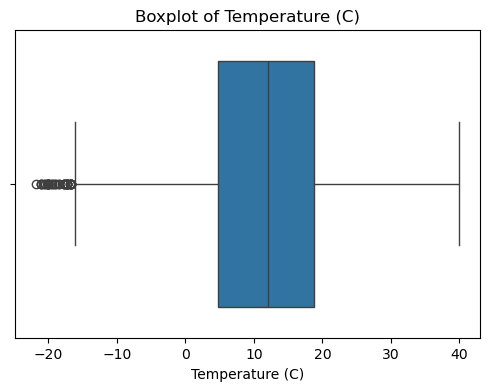

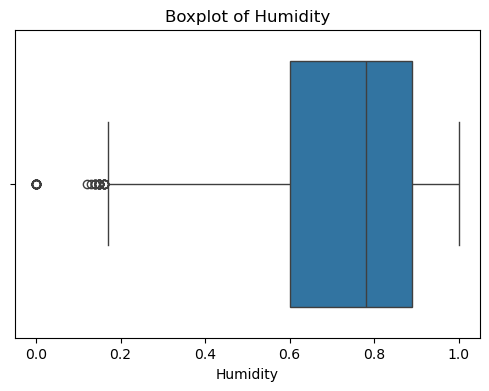

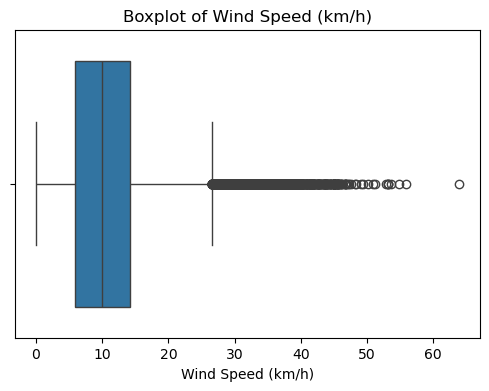

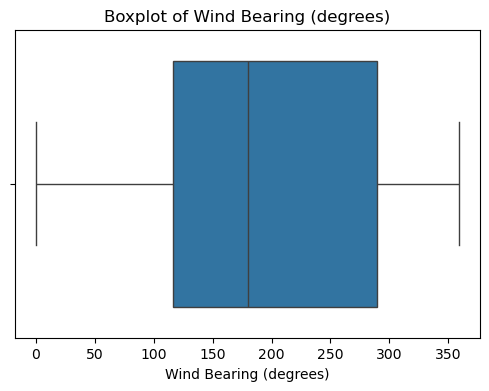

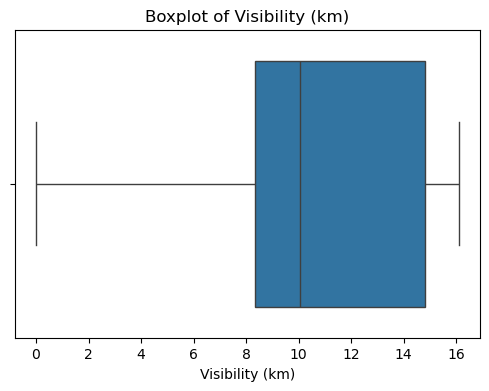

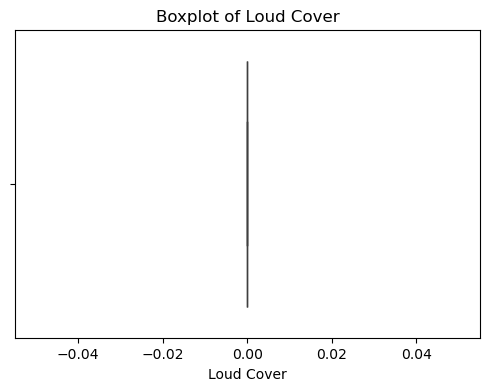

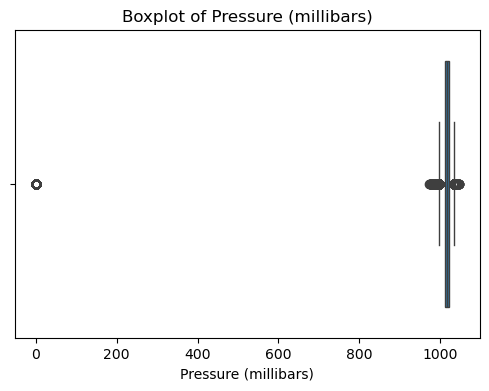

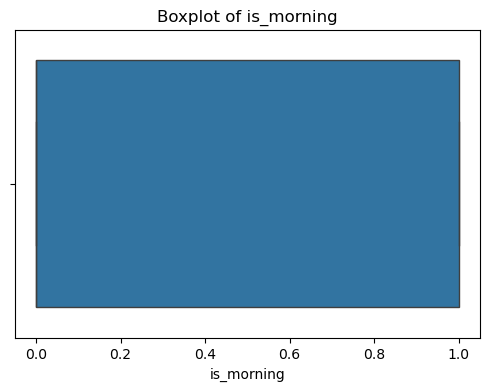

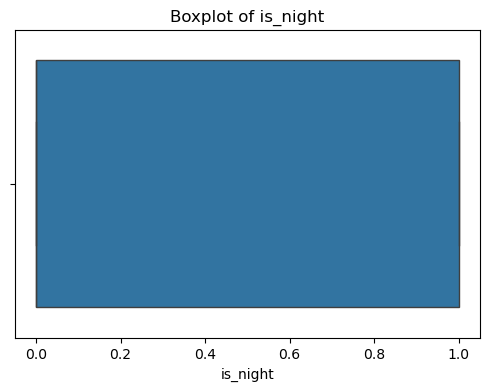

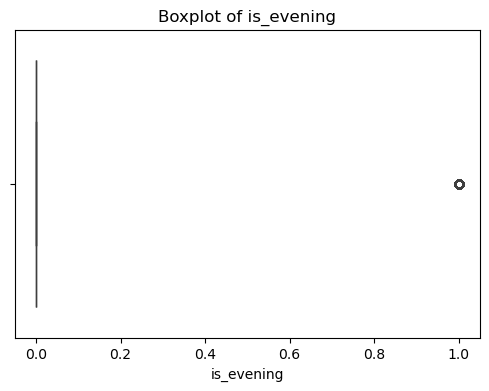

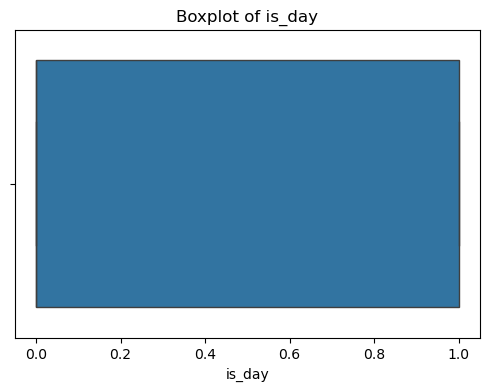

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include=['float64','int64']).columns

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

### Temperaturee Hymidity and Wind Speeed have outliers ......

In [26]:
outlier_summary = []

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append((col, count))

# Convert to DataFrame
import pandas as pd
outlier_df = pd.DataFrame(outlier_summary, columns=['Column', 'Outlier Count'])

print(outlier_df)

                    Column  Outlier Count
0          Temperature (C)             44
1                 Humidity             46
2        Wind Speed (km/h)           3028
3   Wind Bearing (degrees)              0
4          Visibility (km)              0
5               Loud Cover              0
6     Pressure (millibars)           4400
7               is_morning              0
8                 is_night              0
9               is_evening          15356
10                  is_day              0


#### Wind Speed can be ignored as Wind changes regulary...


In [27]:
cols = ['Temperature (C)', 'Humidity']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Capping
    df[col] = df[col].clip(lower, upper)

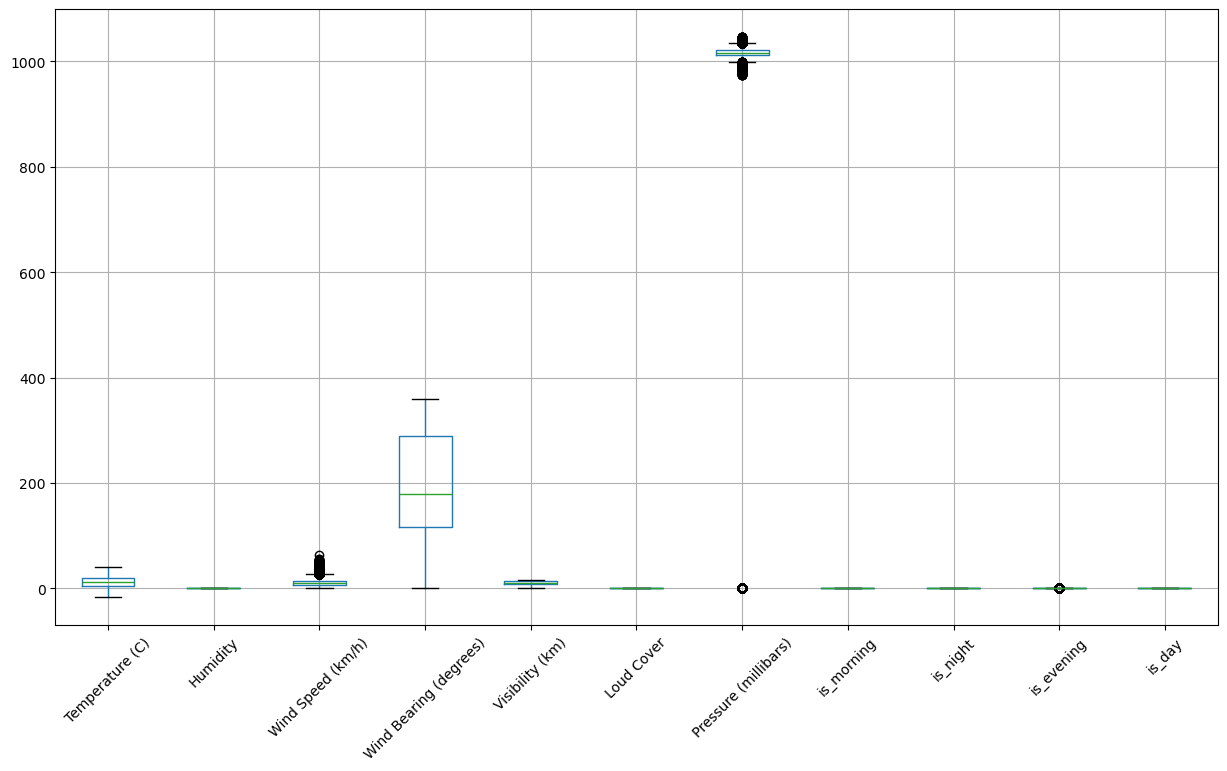

In [28]:
import matplotlib.pyplot as plt

df.select_dtypes(include=['float64','int64']).boxplot(figsize=(15,8))
plt.xticks(rotation=45)
plt.show()

### Univariate Analysis

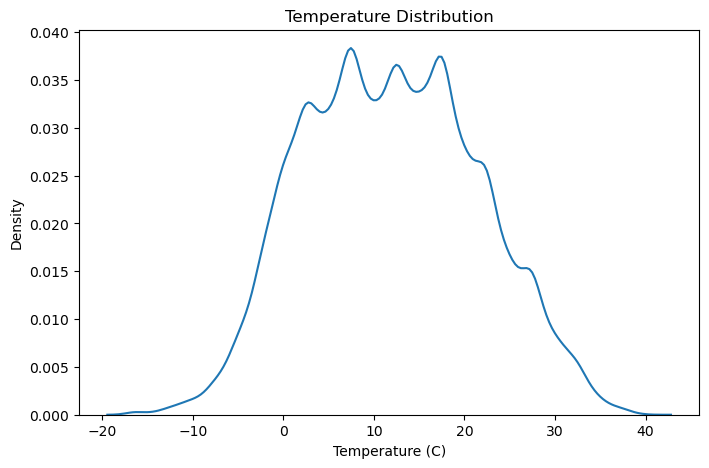

In [29]:
import seaborn as sns
plt.figure(figsize=(8,5))
sns.kdeplot(df['Temperature (C)'])
plt.title("Temperature Distribution")
plt.show()

### Temperature around 10°C is most common and alsmost Normally Distributed!!

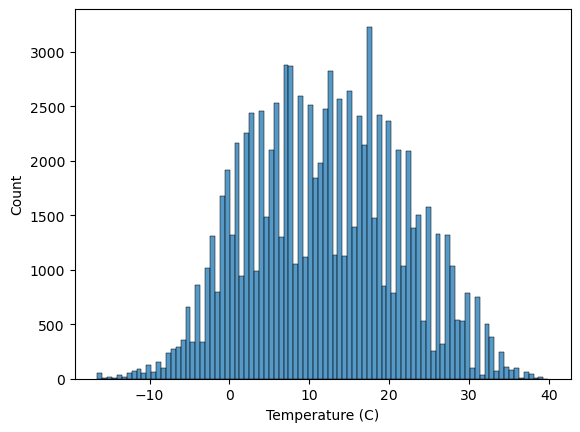

0.0969334639222198


In [30]:
sns.histplot(df['Temperature (C)'])
plt.show()
print(df['Temperature (C)'].skew())

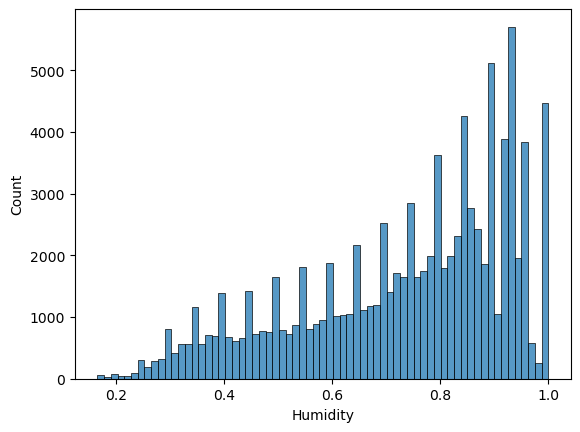

-0.7110219450349485


In [31]:
sns.histplot(df['Humidity'])
plt.show()
print(df['Humidity'].skew())

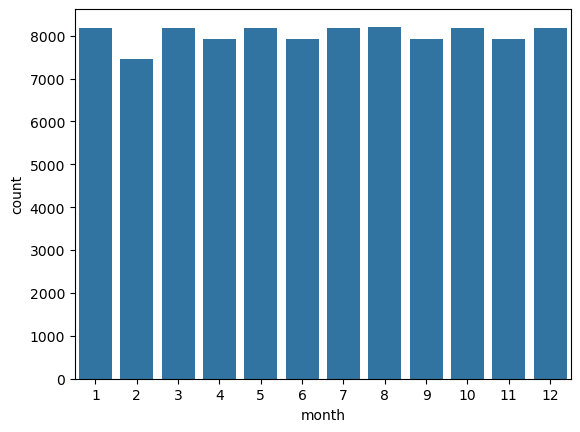

In [32]:
sns.countplot(x=df['month'])
plt.show()

### Bivariate

In [33]:
# sns.pairplot(df)
# plt.show()

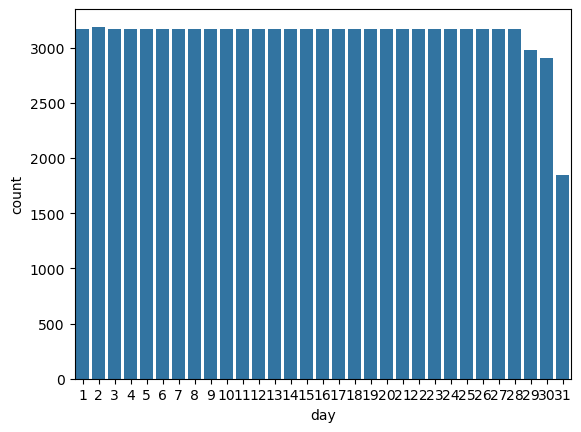

In [34]:
sns.countplot(x=df['day'])
plt.show()

In [35]:
def label_weather(row):
    
    extreme_keywords = ['storm', 'heavy rain', 'tornado', 'heavy snow', 'blustery', 'dangerously']
    moderate_keywords = ['breezy', 'drizzle', 'light rain', 'windy', 'rain']
    
    summary = str(row['Summary']).lower()
    
    # 🔴 Label 2 → Extreme
    if (
        (row['Wind Speed (km/h)'] >= 50) or
        (row['Visibility (km)'] <= 1) or
        (row['Pressure (millibars)'] <= 980) or
        (row['Temperature (C)'] <= -15) or
        (row['Temperature (C)'] >= 40) or
        ((row['Humidity'] >= 0.95) and (row['Wind Speed (km/h)'] >= 25)) or
        any(word in summary for word in extreme_keywords)
    ):
        return 2

    # 🟡 Label 1 → Moderate
    elif (
        (30 <= row['Wind Speed (km/h)'] < 50) or
        (1 < row['Visibility (km)'] <= 5) or
        (980 < row['Pressure (millibars)'] <= 990) or
        ((row['Humidity'] >= 0.90) and (row['Wind Speed (km/h)'] >= 20)) or
        ((row['Temperature (C)'] <= -10) or (row['Temperature (C)'] >= 35)) or
        any(word in summary for word in moderate_keywords)
    ):
        return 1

    # 🟢 Label 0 → Normal
    else:
        return 0

In [36]:
df['Weather_Label'] = df.apply(label_weather, axis=1)

In [37]:
df['Weather_Label'].value_counts()

Weather_Label
0    79920
1    12132
2     4401
Name: count, dtype: int64

In [38]:
label_map = {
    0: 'Normal',
    1: 'Moderate',
    2: 'Extreme'
}

df['Weather_Label_Name'] = df['Weather_Label'].map(label_map)

In [39]:
df['Weather_Label'].value_counts(normalize=True) * 100

Weather_Label
0    82.859009
1    12.578147
2     4.562844
Name: proportion, dtype: float64

In [40]:
(DATA_DIR / 'processed').mkdir(parents=True, exist_ok=True)

df.columns = df.columns.str.strip()

df = df.drop(columns=["Weather_Label_Name","Formatted Date","Daily Summary"])

df.to_csv(DATA_DIR / 'processed' / 'processed_weather.csv', index=False)
df.shape

(96453, 19)

In [41]:
df

,Summary,Precip Type,Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),is_morning,is_night,is_evening,is_day,year,month,day,hour,day_of_week,Weather_Label
0,Partly Cloudy,rain,9.472222,0.89,14.1197,251.0,15.8263,0.0,1015.13,0,0,0,1,2006,3,31,22,4,0
1,Partly Cloudy,rain,9.355556,0.86,14.2646,259.0,15.8263,0.0,1015.63,0,0,0,1,2006,3,31,23,4,0
2,Mostly Cloudy,rain,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,0,0,0,1,2006,4,1,0,5,0
3,Partly Cloudy,rain,8.288889,0.83,14.1036,269.0,15.8263,0.0,1016.41,0,0,0,1,2006,4,1,1,5,0
4,Mostly Cloudy,rain,8.755556,0.83,11.0446,259.0,15.8263,0.0,1016.51,0,0,0,1,2006,4,1,2,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96448,Partly Cloudy,rain,26.016667,0.43,10.9963,31.0,16.1000,0.0,1014.36,1,0,0,0,2016,9,9,17,4,0
96449,Partly Cloudy,rain,24.583333,0.48,10.0947,20.0,15.5526,0.0,1015.16,1,0,0,0,2016,9,9,18,4,0
96450,Partly Cloudy,rain,22.038889,0.56,8.9838,30.0,16.1000,0.0,1015.66,1,0,0,0,2016,9,9,19,4,0
96451,Partly Cloudy,rain,21.522222,0.60,10.5294,20.0,16.1000,0.0,1015.95,1,0,0,0,2016,9,9,20,4,0


🚀 Starting Training...

✅ Logistic Regression Completed. Accuracy: 0.9194
✅ Random Forest Completed. Accuracy: 0.9984
✅ Decision Tree Completed. Accuracy: 0.9999


c:\Users\VISHAL KUSHWAHA\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


✅ AdaBoost Completed. Accuracy: 0.9807
✅ Gradient Boosting Completed. Accuracy: 0.9999
✅ Naive Bayes Completed. Accuracy: 0.8980


c:\Users\VISHAL KUSHWAHA\anaconda3\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


✅ SVC Completed. Accuracy: 0.6794

===== FINAL MODEL RANKING =====
                 Model  Accuracy
4    Gradient Boosting  0.999948
2        Decision Tree  0.999896
1        Random Forest  0.998445
3             AdaBoost  0.980716
0  Logistic Regression  0.919392
5          Naive Bayes  0.897984
6                  SVC  0.679384


C:\Users\VISHAL KUSHWAHA\AppData\Local\Temp\ipykernel_22700\1658080654.py:106: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=comparison_df, palette='viridis')


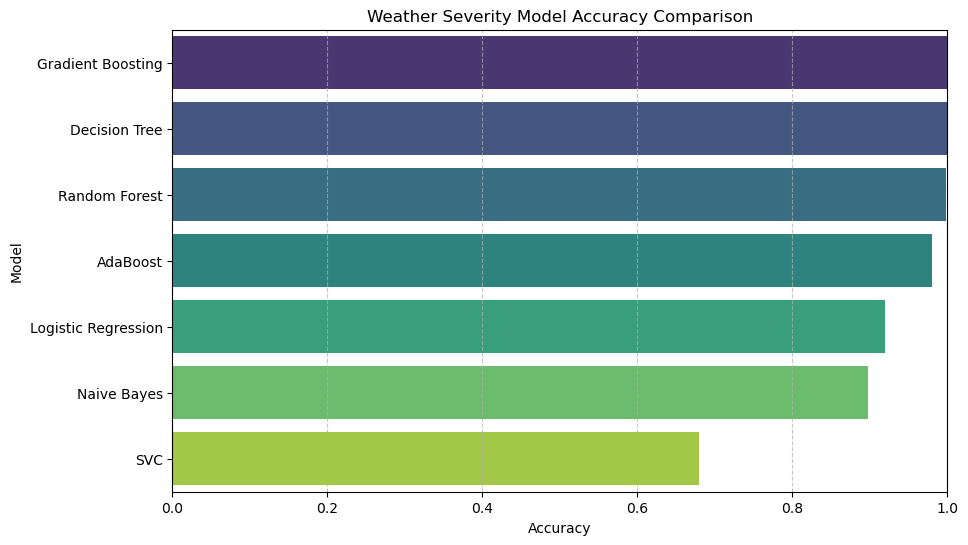

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Model Imports
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# ==============================
# 1. LOAD & PREPROCESS (Based on your EDA)
# ==============================
# Assuming df is already loaded. 
# Removing 'Apparent Temperature (C)' due to multicollinearity (r=0.99)
if 'Apparent Temperature (C)' in df.columns:
    df = df.drop(columns=['Apparent Temperature (C)'])

# Define Features and Target
# Using 'Weather_Label' as target as per your EDA report
X = df.drop(columns=['Weather_Label', 'Weather_Label_Name', 'Formatted Date'], errors='ignore')
y = df['Weather_Label']

# ==============================
# 2. IDENTIFY COLUMN TYPES
# ==============================
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# ==============================
# 3. PREPROCESSING PIPELINE
# ==============================
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# ==============================
# 4. TRAIN-TEST SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==============================
# 5. DEFINE ALL MODELS
# ==============================
# Note: SVC can be very slow on 96k rows; LinearSVC or sampling is recommended 
# but I have kept SVC(kernel='linear') per your request.
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42, algorithm='SAMME'),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVC": SVC(kernel='linear', class_weight='balanced', max_iter=2000) # Added max_iter to prevent infinite loop
}

# ==============================
# 6. TRAIN AND EVALUATE
# ==============================
results = []

print("🚀 Starting Training...\n")

for name, model in models.items():
    # Create the full pipeline for each model
    clf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Fit model
    clf_pipeline.fit(X_train, y_train)
    
    # Predict
    y_pred = clf_pipeline.predict(X_test)
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": acc})
    
    print(f"✅ {name} Completed. Accuracy: {acc:.4f}")

# ==============================
# 7. COMPARISON & VISUALIZATION
# ==============================
comparison_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)

print("\n===== FINAL MODEL RANKING =====")
print(comparison_df)

# Plotting the results
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Model', data=comparison_df, palette='viridis')
plt.title('Weather Severity Model Accuracy Comparison')
plt.xlim(0, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [43]:
!pip install xgboost

🚀 Starting Training...

✅ Logistic Regression Done | Acc: 0.9194 | F1: 0.8596
✅ Decision Tree Done | Acc: 0.9999 | F1: 0.9995
✅ KNN (k=7) Done | Acc: 0.9624 | F1: 0.9087
✅ SVM (RBF) Done | Acc: 0.9694 | F1: 0.9426
✅ Gradient Boosting Done | Acc: 0.9999 | F1: 0.9997
✅ Random Forest Done | Acc: 0.9984 | F1: 0.9955


c:\Users\VISHAL KUSHWAHA\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:19:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


✅ XGBoost Done | Acc: 0.9921 | F1: 0.9772

===== FINAL PERFORMANCE TABLE =====
         Classifier  Accuracy  F1-score  Precision   Recall
      Decision Tree     100.0  0.999484   0.999484 0.999484
  Gradient Boosting     100.0  0.999742   0.999863 0.999621
      Random Forest      99.8  0.995465   0.997513 0.993448
            XGBoost      99.2  0.977187   0.976678 0.977722
          SVM (RBF)      96.9  0.942639   0.919839 0.968914
          KNN (k=7)      96.2  0.908742   0.921627 0.896608
Logistic Regression      91.9  0.859629   0.818242 0.916278


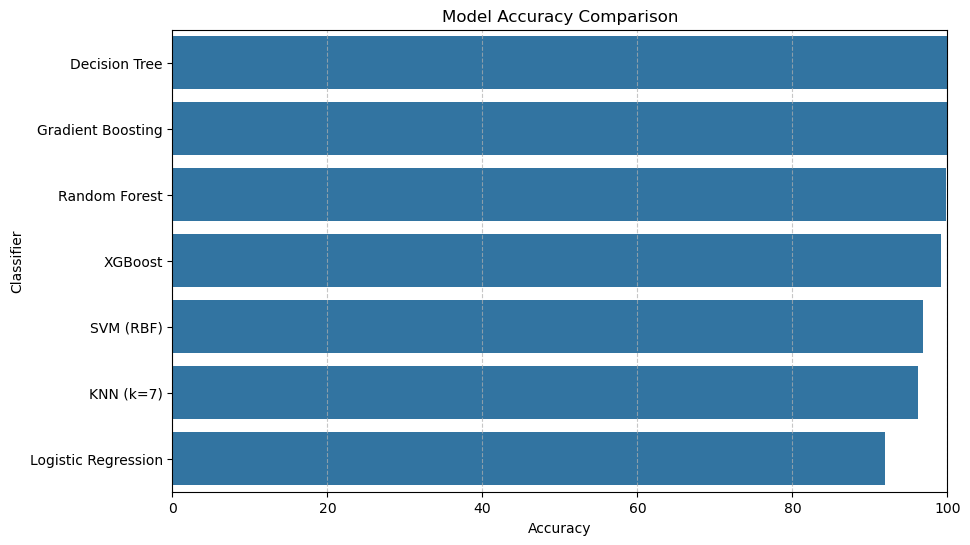


===== LATEX TABLE =====
\begin{tabular}{lrrrr}
\toprule
Classifier & Accuracy & F1-score & Precision & Recall \\
\midrule
Decision Tree & 100.000000 & 0.999484 & 0.999484 & 0.999484 \\
Gradient Boosting & 100.000000 & 0.999742 & 0.999863 & 0.999621 \\
Random Forest & 99.800000 & 0.995465 & 0.997513 & 0.993448 \\
XGBoost & 99.200000 & 0.977187 & 0.976678 & 0.977722 \\
SVM (RBF) & 96.900000 & 0.942639 & 0.919839 & 0.968914 \\
KNN (k=7) & 96.200000 & 0.908742 & 0.921627 & 0.896608 \\
Logistic Regression & 91.900000 & 0.859629 & 0.818242 & 0.916278 \\
\bottomrule
\end{tabular}



In [44]:
# ==============================
# 0. IMPORT LIBRARIES
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# ==============================
# 1. LOAD DATA
# ==============================
# Replace with your dataset path if needed
# df = pd.read_csv("your_dataset.csv")

# ==============================
# 2. PREPROCESSING
# ==============================
# Drop highly correlated column
if 'Apparent Temperature (C)' in df.columns:
    df = df.drop(columns=['Apparent Temperature (C)'])

# Features & Target
X = df.drop(columns=['Weather_Label', 'Weather_Label_Name', 'Formatted Date'], errors='ignore')
y = df['Weather_Label']

# Column types
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# ==============================
# 3. TRAIN-TEST SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==============================
# 4. MODELS
# ==============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)": SVC(kernel='rbf', class_weight='balanced'),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
}

# ==============================
# 5. TRAIN & EVALUATE
# ==============================
results = []

print("🚀 Starting Training...\n")

for name, model in models.items():
    
    clf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train
    clf_pipeline.fit(X_train, y_train)
    
    # Predict
    y_pred = clf_pipeline.predict(X_test)
    
    # Metrics (Macro for multi-class)
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    
    results.append({
        "Classifier": name,
        "Accuracy": acc,
        "F1-score": f1,
        "Precision": precision,
        "Recall": recall
    })
    
    print(f"✅ {name} Done | Acc: {acc:.4f} | F1: {f1:.4f}")

# ==============================
# 6. FINAL TABLE
# ==============================
comparison_df = pd.DataFrame(results)

# Convert Accuracy to %
comparison_df["Accuracy"] = (comparison_df["Accuracy"] * 100).round(1)

# Sort
comparison_df = comparison_df.sort_values(by="Accuracy", ascending=False)

print("\n===== FINAL PERFORMANCE TABLE =====")
print(comparison_df.to_string(index=False))

# ==============================
# 7. VISUALIZATION
# ==============================
plt.figure(figsize=(10, 6))
sns.barplot(x='Accuracy', y='Classifier', data=comparison_df)
plt.title('Model Accuracy Comparison')
plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# ==============================
# 8. SAVE RESULTS (OPTIONAL)
# ==============================
comparison_df.to_csv(METRICS_DIR / "model_performance.csv", index=False)

# LaTeX table (for report/paper)
print("\n===== LATEX TABLE =====")
print(comparison_df.to_latex(index=False))

🚀 Starting Training + Cross Validation...

✅ Logistic Regression
   CV Accuracy: 0.9219
   Test Accuracy: 0.9194

✅ Decision Tree
   CV Accuracy: 0.9999
   Test Accuracy: 0.9999

✅ KNN (k=7)
   CV Accuracy: 0.9634
   Test Accuracy: 0.9624

✅ SVM (RBF)
   CV Accuracy: 0.9709
   Test Accuracy: 0.9694

✅ Gradient Boosting
   CV Accuracy: 0.9999
   Test Accuracy: 0.9999

✅ Random Forest
   CV Accuracy: 0.9985
   Test Accuracy: 0.9984



c:\Users\VISHAL KUSHWAHA\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:26:06] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


✅ XGBoost
   CV Accuracy: 0.9927
   Test Accuracy: 0.9921


===== FINAL PERFORMANCE TABLE =====
         Classifier  Test Accuracy (%)  CV Accuracy (%)  F1-score  Precision   Recall
      Decision Tree              100.0            100.0  0.999484   0.999484 0.999484
  Gradient Boosting              100.0            100.0  0.999742   0.999863 0.999621
      Random Forest               99.8             99.9  0.995465   0.997513 0.993448
            XGBoost               99.2             99.3  0.977187   0.976678 0.977722
          SVM (RBF)               96.9             97.1  0.942639   0.919839 0.968914
          KNN (k=7)               96.2             96.3  0.908742   0.921627 0.896608
Logistic Regression               91.9             92.2  0.859629   0.818242 0.916278


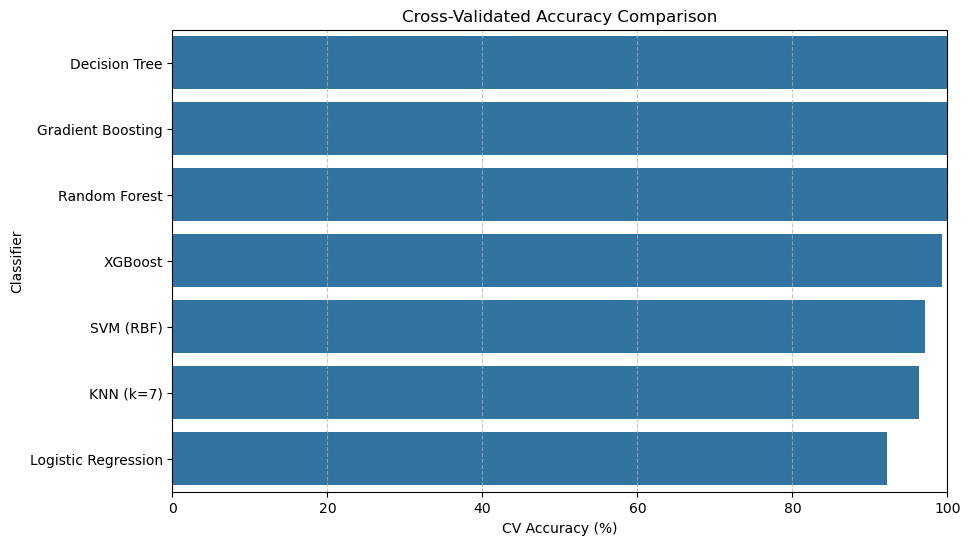


===== LATEX TABLE =====
\begin{tabular}{lrrrrr}
\toprule
Classifier & Test Accuracy (%) & CV Accuracy (%) & F1-score & Precision & Recall \\
\midrule
Decision Tree & 100.000000 & 100.000000 & 0.999484 & 0.999484 & 0.999484 \\
Gradient Boosting & 100.000000 & 100.000000 & 0.999742 & 0.999863 & 0.999621 \\
Random Forest & 99.800000 & 99.900000 & 0.995465 & 0.997513 & 0.993448 \\
XGBoost & 99.200000 & 99.300000 & 0.977187 & 0.976678 & 0.977722 \\
SVM (RBF) & 96.900000 & 97.100000 & 0.942639 & 0.919839 & 0.968914 \\
KNN (k=7) & 96.200000 & 96.300000 & 0.908742 & 0.921627 & 0.896608 \\
Logistic Regression & 91.900000 & 92.200000 & 0.859629 & 0.818242 & 0.916278 \\
\bottomrule
\end{tabular}



In [45]:
# ==============================
# 0. IMPORT LIBRARIES
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# ==============================
# 1. LOAD DATA
# ==============================
# df = pd.read_csv("your_dataset.csv")

# ==============================
# 2. PREPROCESSING
# ==============================
if 'Apparent Temperature (C)' in df.columns:
    df = df.drop(columns=['Apparent Temperature (C)'])

X = df.drop(columns=['Weather_Label', 'Weather_Label_Name', 'Formatted Date'], errors='ignore')
y = df['Weather_Label']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# ==============================
# 3. TRAIN-TEST SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==============================
# 4. MODELS
# ==============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)": SVC(kernel='rbf', class_weight='balanced'),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
}

# ==============================
# 5. CROSS VALIDATION SETUP
# ==============================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ==============================
# 6. TRAIN, CV & EVALUATE
# ==============================
results = []

print("🚀 Starting Training + Cross Validation...\n")

for name, model in models.items():
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # ------------------------------
    # Cross Validation Score
    # ------------------------------
    cv_scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv, scoring='accuracy', n_jobs=-1
    )
    
    cv_mean = cv_scores.mean()
    
    # ------------------------------
    # Train on full training set
    # ------------------------------
    pipeline.fit(X_train, y_train)
    
    # Test Prediction
    y_pred = pipeline.predict(X_test)
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    
    results.append({
        "Classifier": name,
        "Test Accuracy (%)": acc * 100,
        "CV Accuracy (%)": cv_mean * 100,
        "F1-score": f1,
        "Precision": precision,
        "Recall": recall
    })
    
    print(f"✅ {name}")
    print(f"   CV Accuracy: {cv_mean:.4f}")
    print(f"   Test Accuracy: {acc:.4f}\n")

# ==============================
# 7. FINAL TABLE
# ==============================
comparison_df = pd.DataFrame(results)

comparison_df["Test Accuracy (%)"] = comparison_df["Test Accuracy (%)"].round(1)
comparison_df["CV Accuracy (%)"] = comparison_df["CV Accuracy (%)"].round(1)

comparison_df = comparison_df.sort_values(by="CV Accuracy (%)", ascending=False)

print("\n===== FINAL PERFORMANCE TABLE =====")
print(comparison_df.to_string(index=False))

# ==============================
# 8. VISUALIZATION
# ==============================
plt.figure(figsize=(10, 6))
sns.barplot(x='CV Accuracy (%)', y='Classifier', data=comparison_df)
plt.title('Cross-Validated Accuracy Comparison')
plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# ==============================
# 9. SAVE RESULTS
# ==============================
comparison_df.to_csv(METRICS_DIR / "model_performance_cv.csv", index=False)

print("\n===== LATEX TABLE =====")
print(comparison_df.to_latex(index=False))


📊 Generating Confusion Matrices...



c:\Users\VISHAL KUSHWAHA\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:29:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


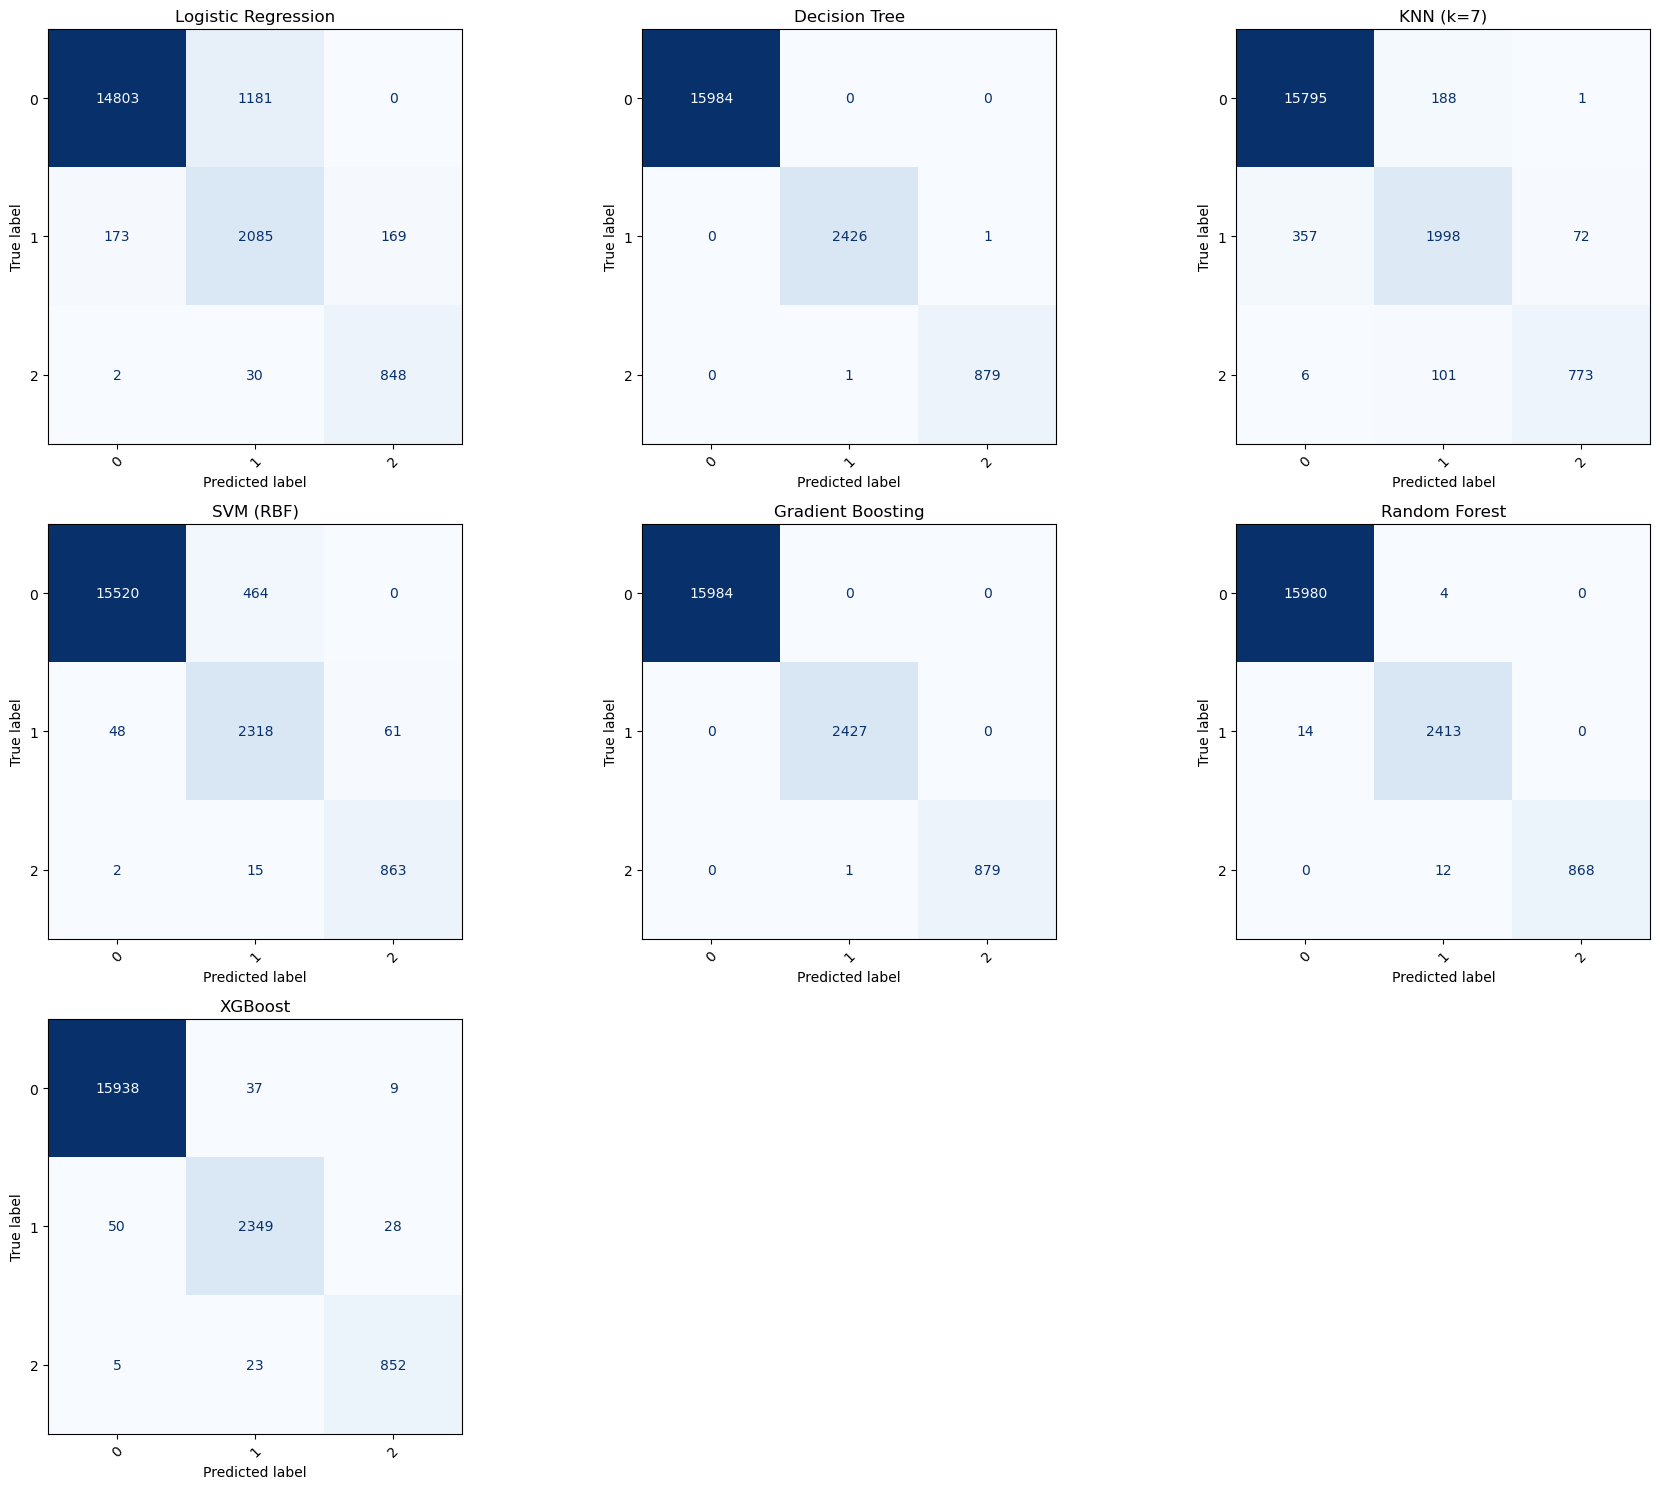

In [46]:
# ==============================
# CONFUSION MATRIX FOR ALL MODELS
# ==============================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("\n📊 Generating Confusion Matrices...\n")

# Number of models
n_models = len(models)

# Create subplot grid
cols = 3
rows = int(np.ceil(n_models / cols))

plt.figure(figsize=(18, 5 * rows))

for idx, (name, model) in enumerate(models.items(), 1):
    
    # Pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train
    pipeline.fit(X_train, y_train)
    
    # Predict
    y_pred = pipeline.predict(X_test)
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    
    # Plot
    plt.subplot(rows, cols, idx)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues', ax=plt.gca(), colorbar=False)
    
    plt.title(name)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Select 2 features only (IMPORTANT)
X = df[['Temperature (C)', 'Humidity']].values
y = df['Weather_Label'].values

# Scale data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Mesh grid function
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y)
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

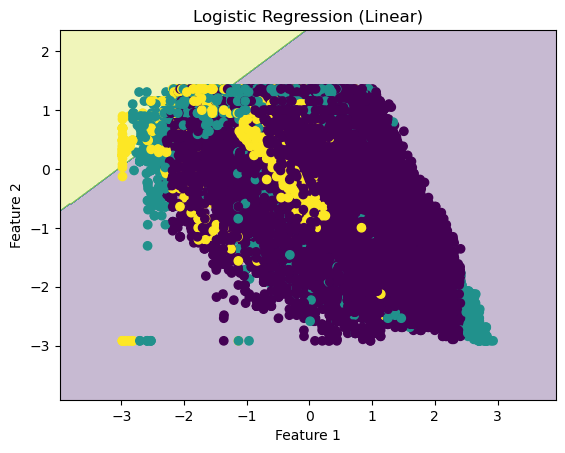

In [48]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression()
model_lr.fit(X, y)

plot_decision_boundary(model_lr, X, y, "Logistic Regression (Linear)")

In [49]:
df['year'].value_counts()

year
2010    8784
2008    8784
2012    8784
2016    8783
2011    8760
2007    8760
2006    8760
2009    8760
2015    8760
2013    8760
2014    8757
2005       1
Name: count, dtype: int64

✅ Logistic Regression trained
✅ Decision Tree trained
✅ Random Forest trained
✅ Gradient Boosting trained
✅ KNN trained


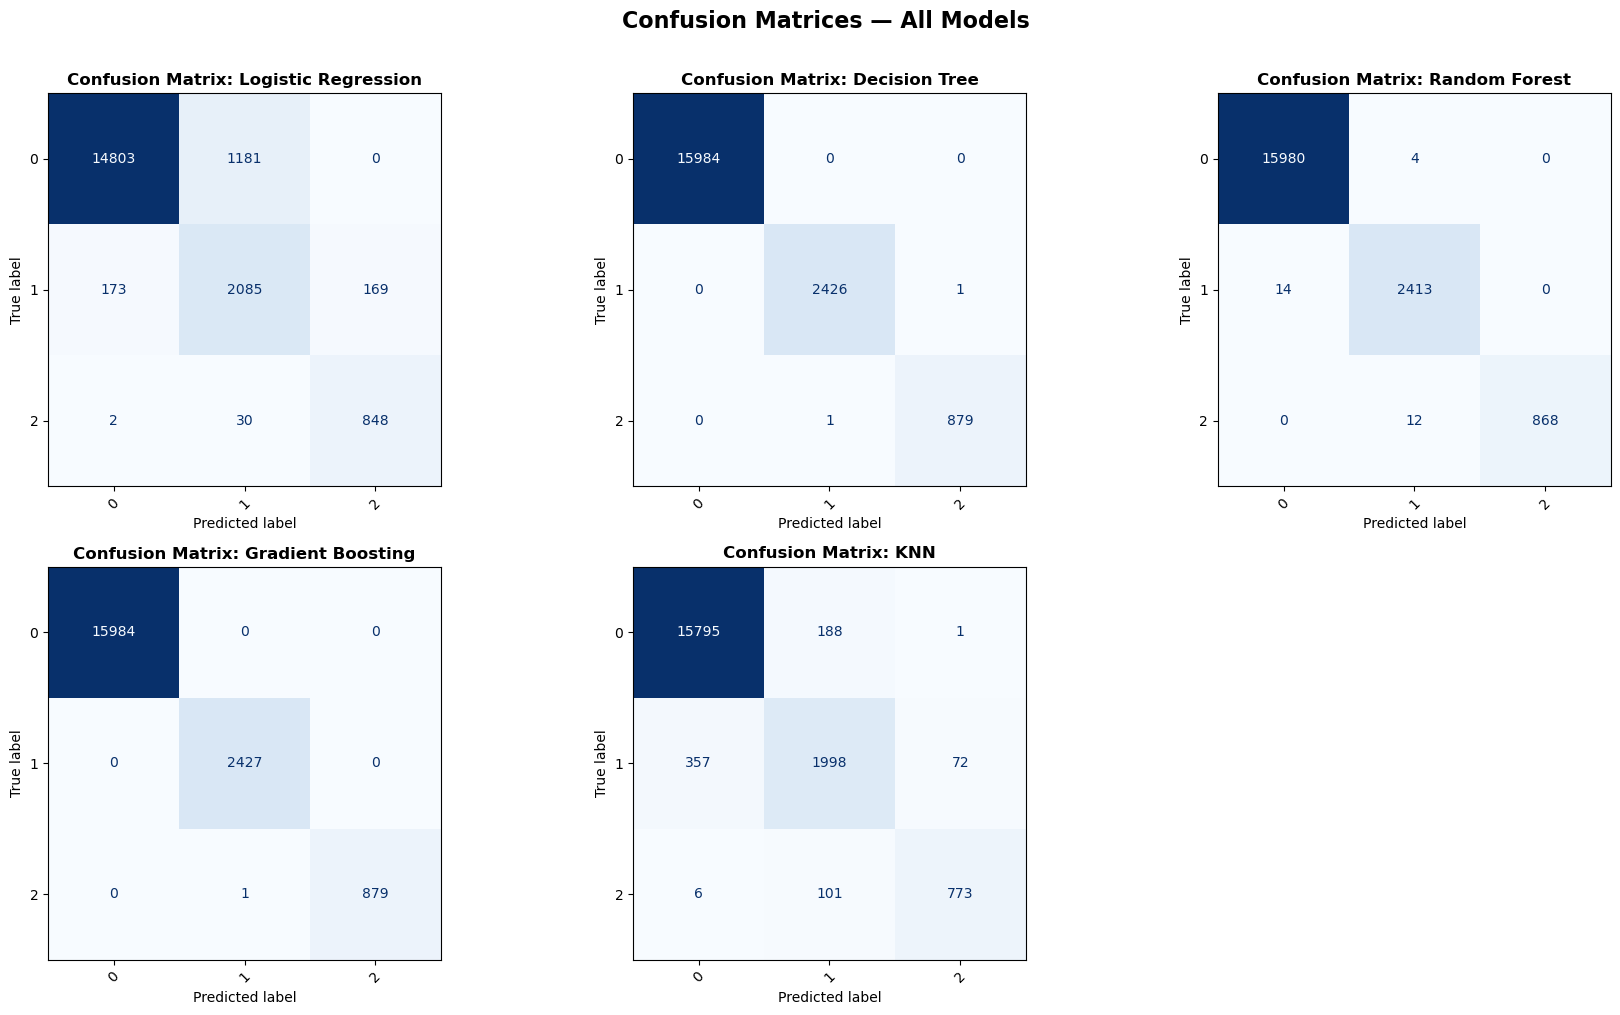

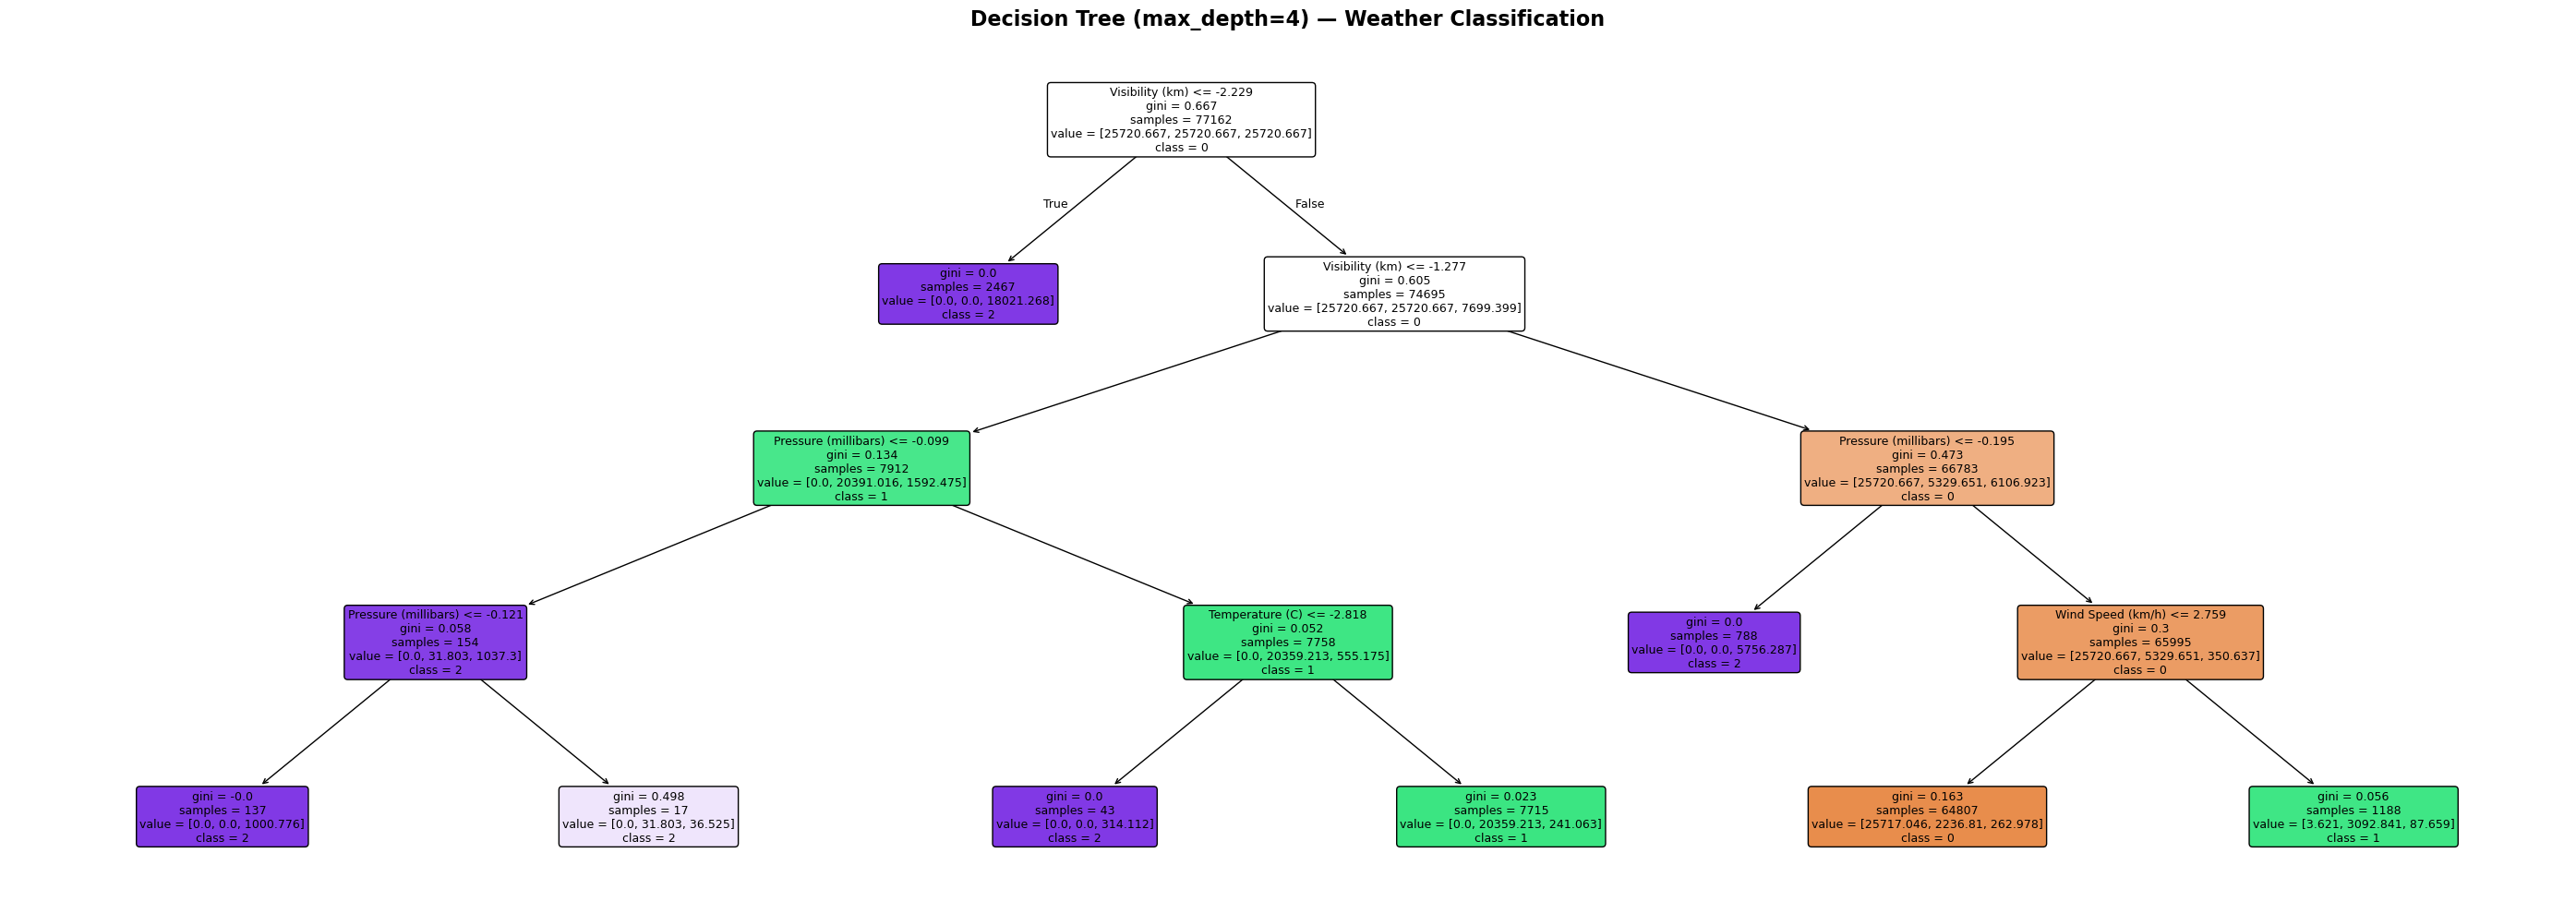

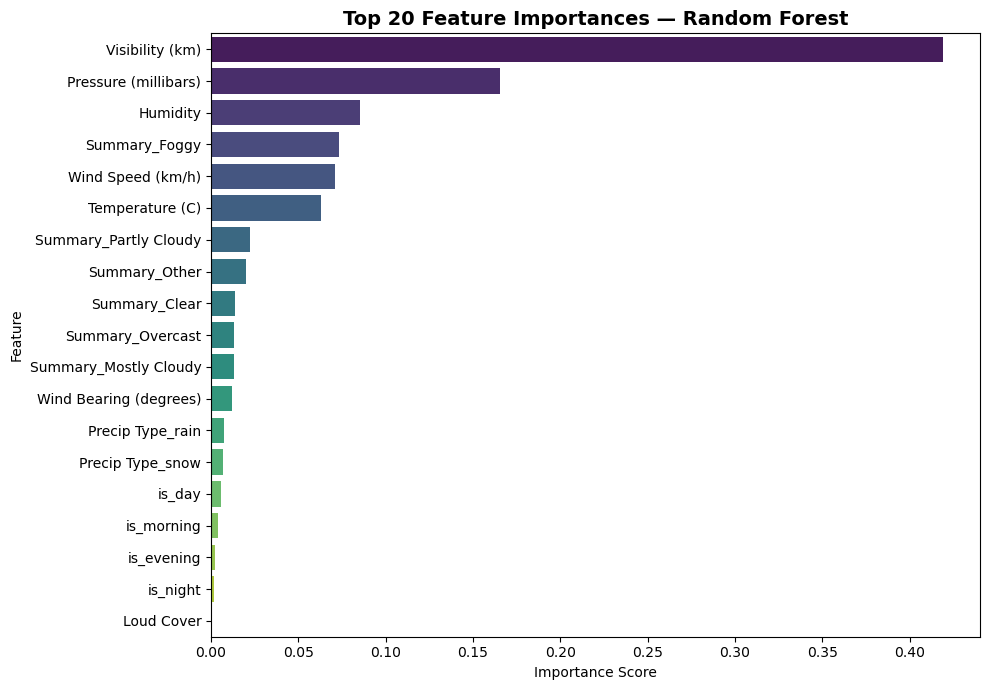

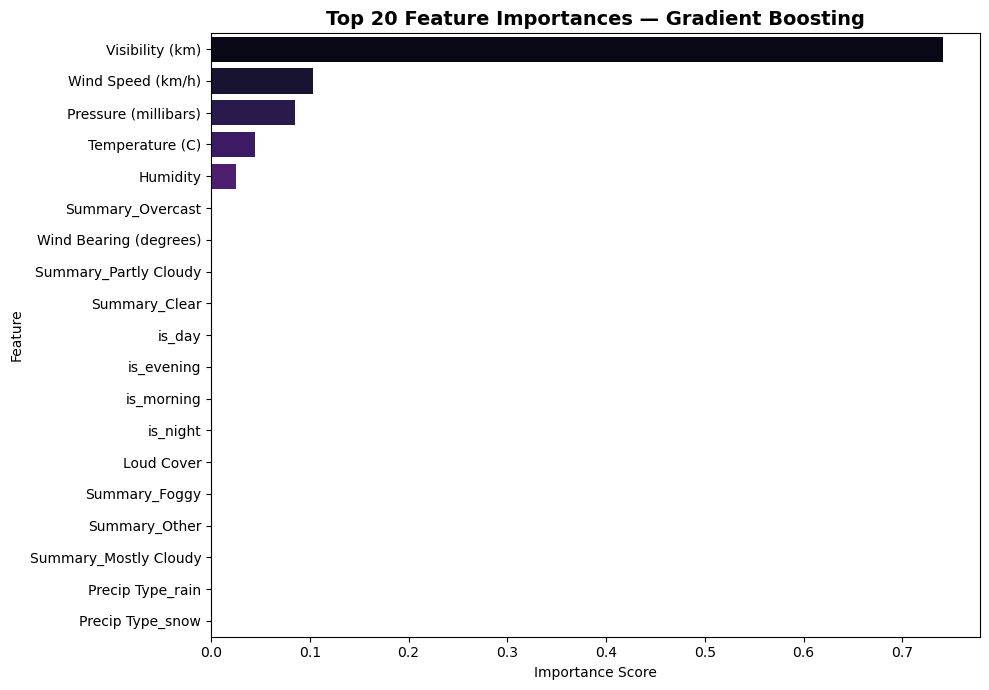

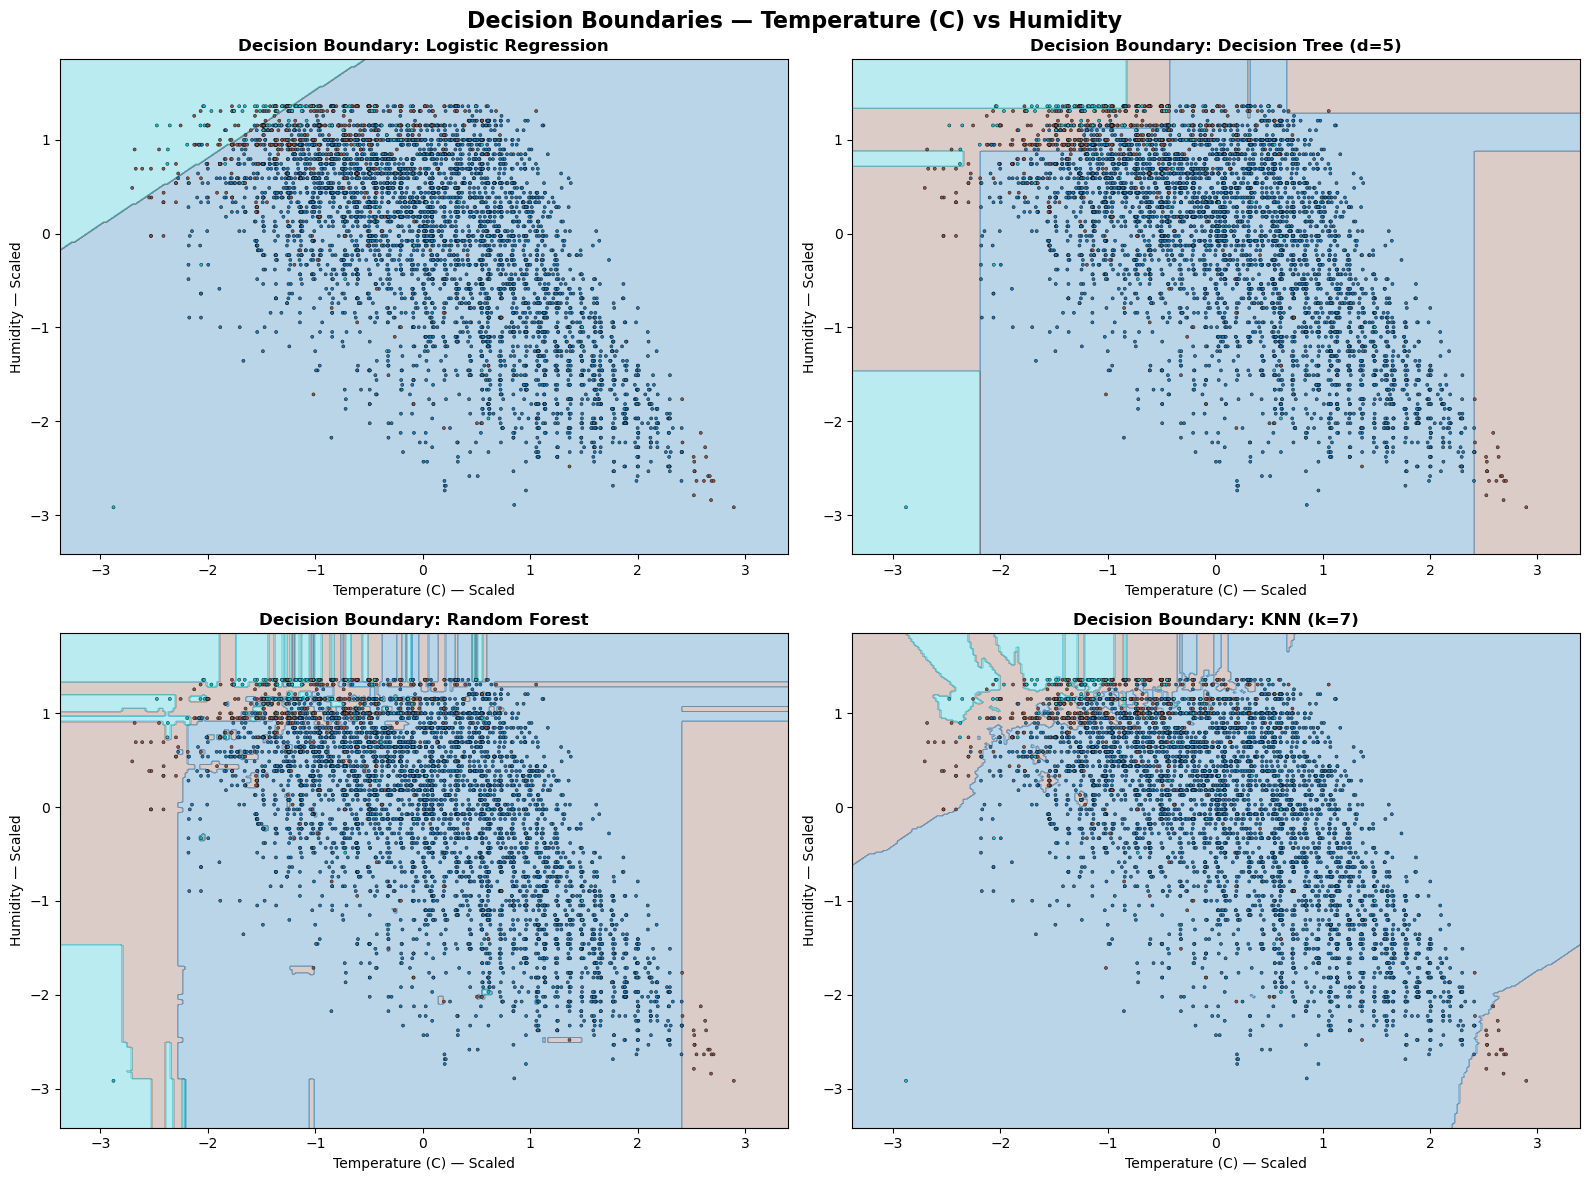

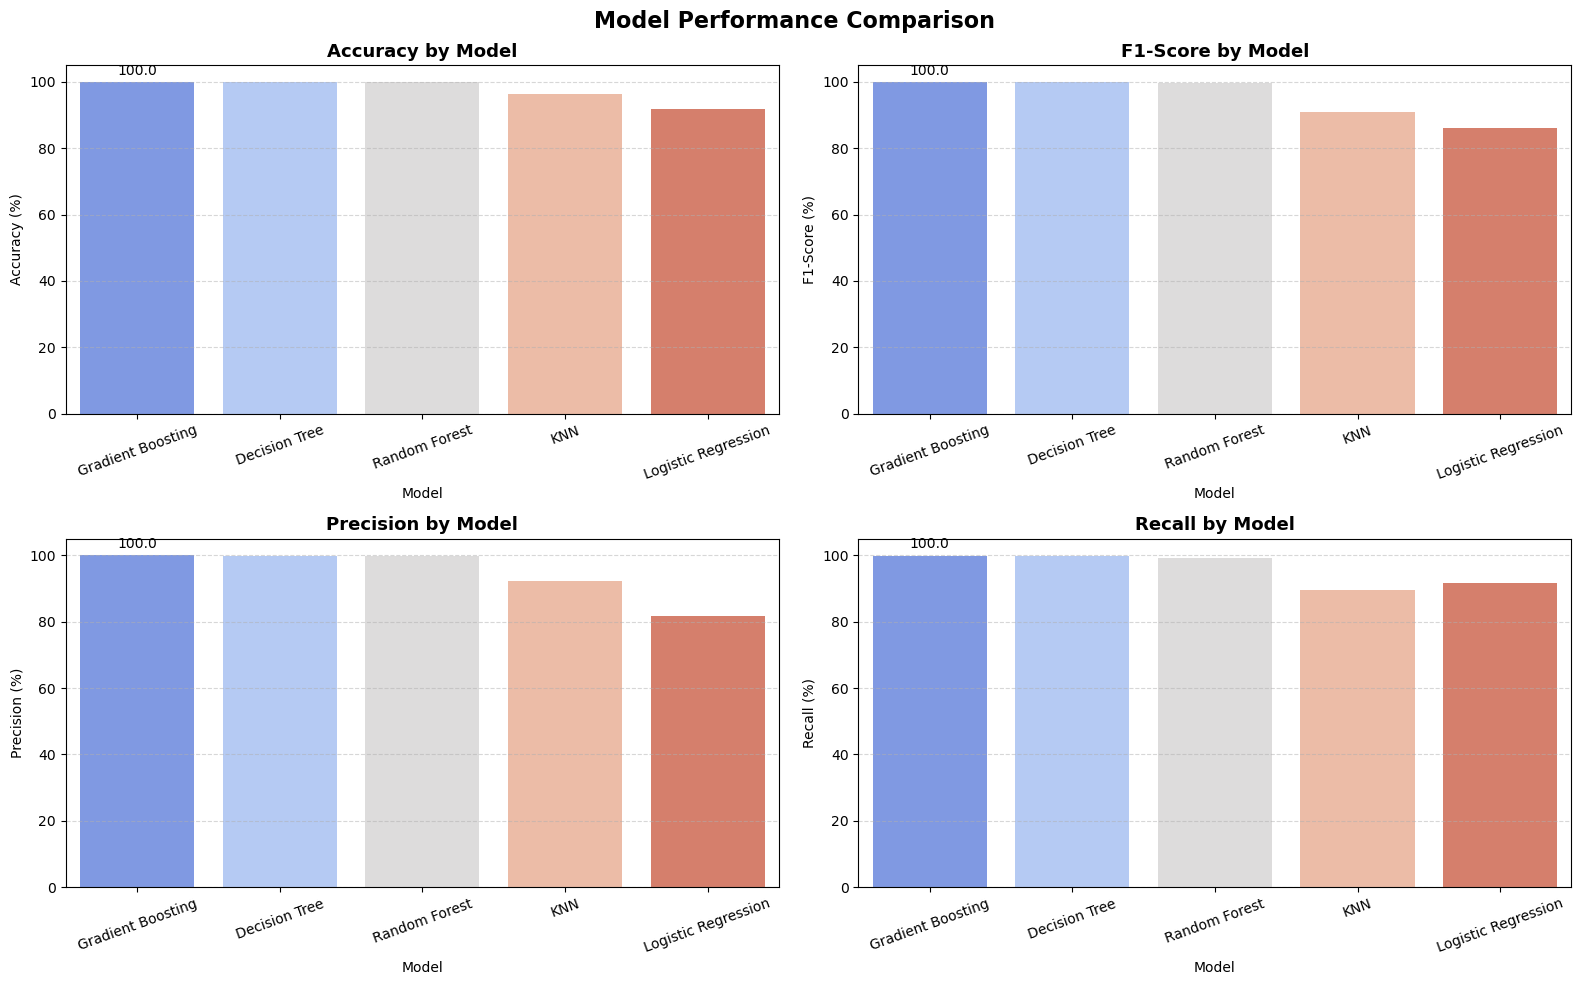

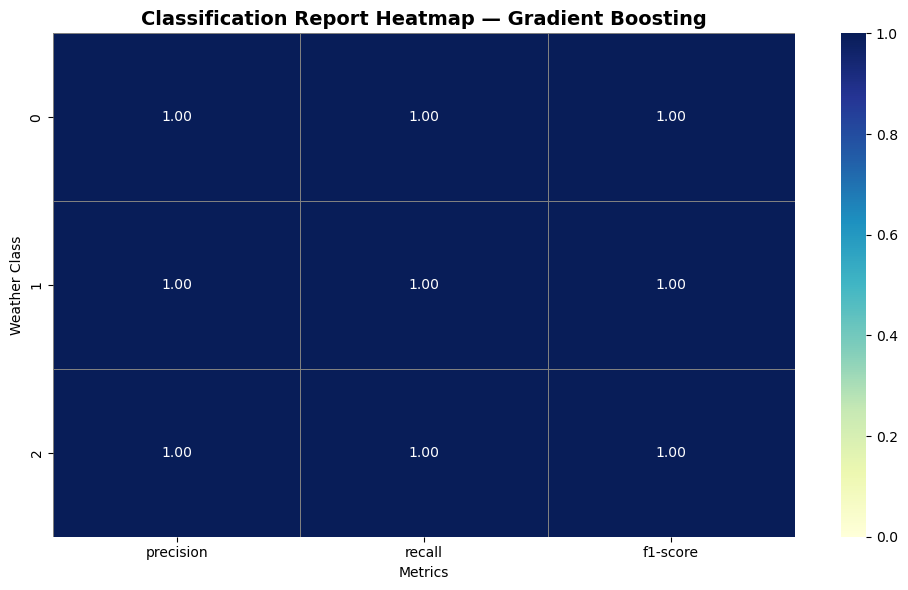

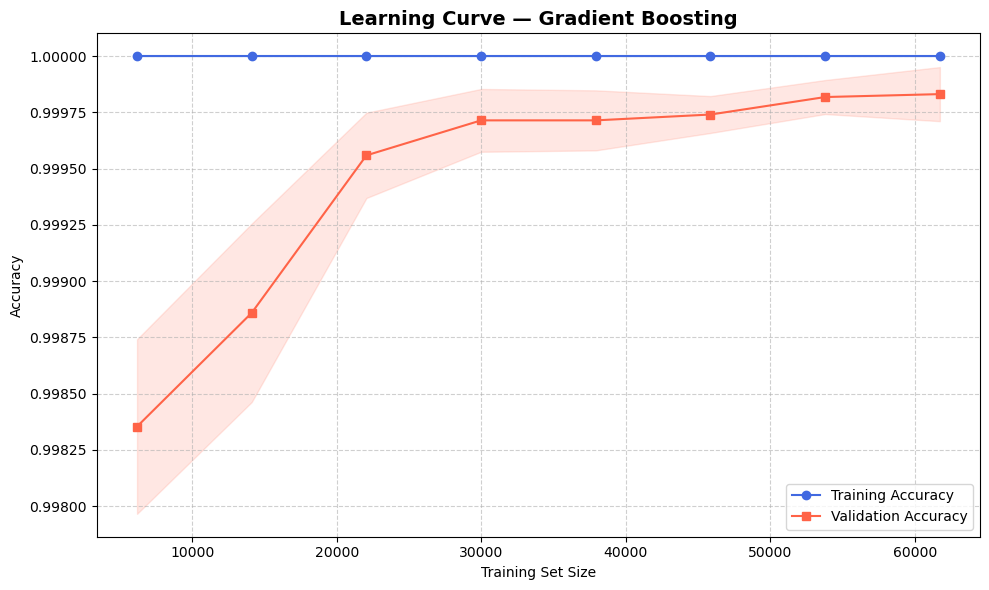

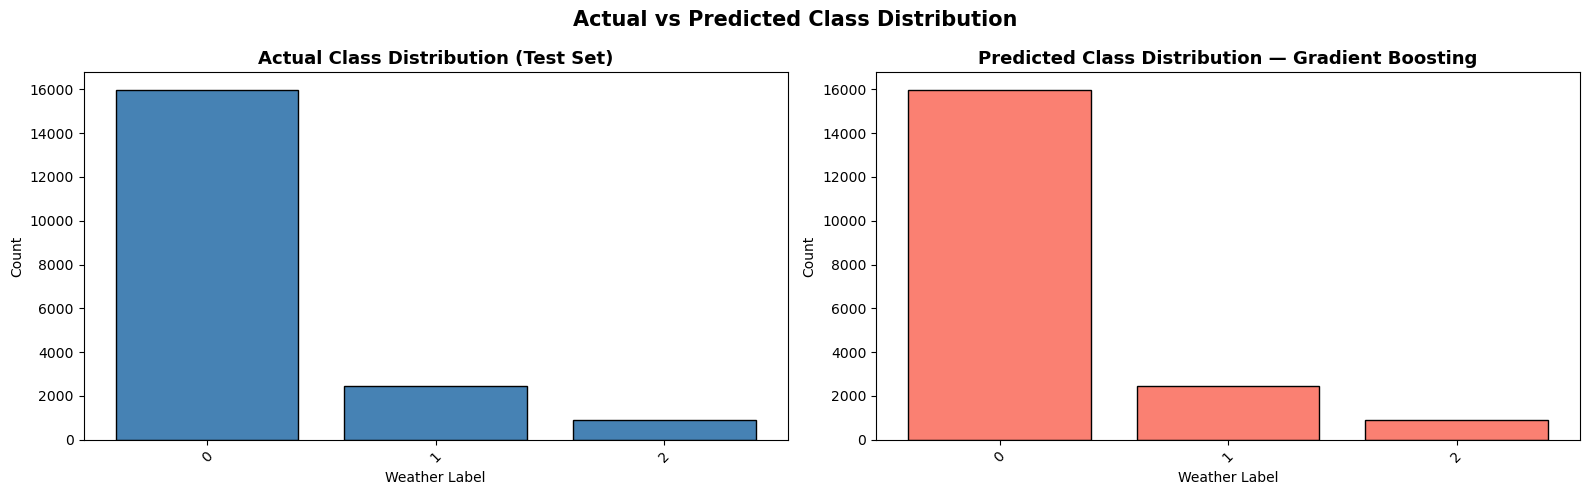

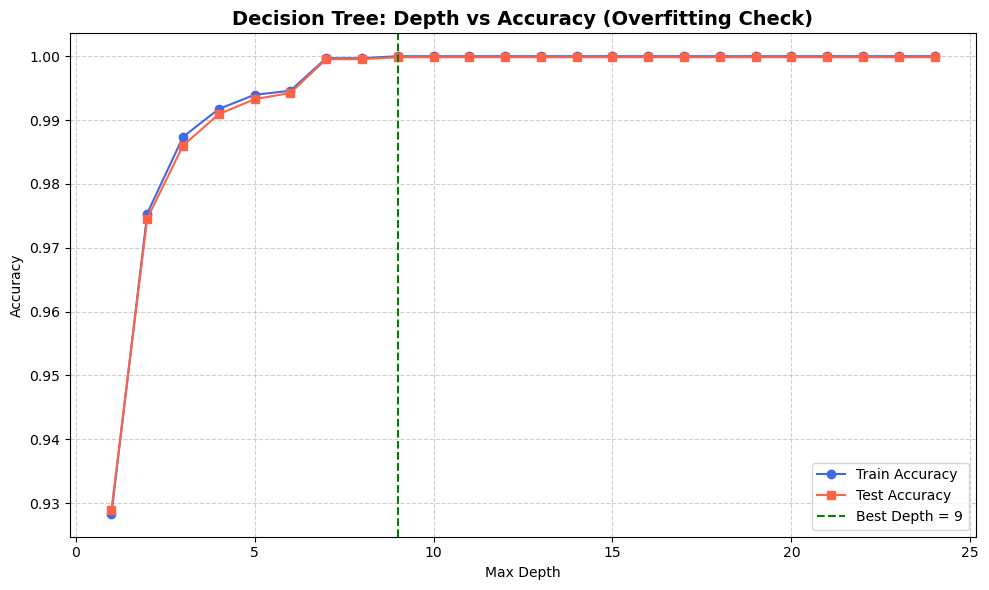


✅ ALL PLOTS GENERATED SUCCESSFULLY!
Saved files: confusion_matrices.png, decision_tree_plot.png, feature_importance_rf.png,
             feature_importance_gb.png, decision_boundaries.png, model_comparison.png,
             classification_report_heatmap.png, learning_curve.png,
             actual_vs_predicted_distribution.png, tree_depth_vs_accuracy.png


In [50]:
# ============================================================
# COMPLETE MODEL VISUALIZATION CODE
# Weather Classification - weatherHistory.csv
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier

# ============================================================
# PREPROCESSING (matching your EDA notebook)
# ============================================================

# df = pd.read_csv('data/weatherHistory.csv')   # ← already loaded in your notebook

if 'Apparent Temperature (C)' in df.columns:
    df = df.drop(columns=['Apparent Temperature (C)'])

X = df.drop(columns=['Weather_Label', 'Weather_Label_Name', 'Formatted Date'], errors='ignore')
y = df['Weather_Label']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ============================================================
# DEFINE MODELS
# ============================================================

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree":       DecisionTreeClassifier(class_weight='balanced', random_state=42, max_depth=10),
    "Random Forest":       RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
}

# Train all pipelines and store predictions
trained_pipelines = {}
y_preds = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    y_preds[name] = pipe.predict(X_test)
    print(f"✅ {name} trained")


# ============================================================
# PLOT 1: CONFUSION MATRICES (all models in one figure)
# ============================================================

class_names = sorted(y.unique())
n_models = len(models)
cols_grid = 3
rows_grid = int(np.ceil(n_models / cols_grid))

fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(18, 5 * rows_grid))
axes = axes.flatten()

for idx, (name, pipe) in enumerate(trained_pipelines.items()):
    cm = confusion_matrix(y_test, y_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap='Blues', ax=axes[idx], colorbar=False)
    axes[idx].set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight='bold')
    axes[idx].tick_params(axis='x', rotation=45)

# Hide unused subplots
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Confusion Matrices — All Models", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 2: DECISION TREE VISUALIZATION (shallow tree for clarity)
# ============================================================

dt_simple = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
pipe_dt_simple = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', dt_simple)])
pipe_dt_simple.fit(X_train, y_train)

# Get feature names after preprocessing
ohe_feature_names = []
if cat_cols:
    ohe = pipe_dt_simple.named_steps['preprocessor'].named_transformers_['cat']
    ohe_feature_names = list(ohe.get_feature_names_out(cat_cols))

all_feature_names = num_cols + ohe_feature_names

plt.figure(figsize=(28, 10))
plot_tree(
    pipe_dt_simple.named_steps['classifier'],
    feature_names=all_feature_names,
    class_names=[str(c) for c in class_names],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=4,
    impurity=True,
    proportion=False
)
plt.title("Decision Tree (max_depth=4) — Weather Classification", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "decision_tree_plot.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 3: FEATURE IMPORTANCE — Random Forest
# ============================================================

rf_pipe = trained_pipelines["Random Forest"]
importances = rf_pipe.named_steps['classifier'].feature_importances_

ohe_feature_names_rf = []
if cat_cols:
    ohe_rf = rf_pipe.named_steps['preprocessor'].named_transformers_['cat']
    ohe_feature_names_rf = list(ohe_rf.get_feature_names_out(cat_cols))

feat_names = num_cols + ohe_feature_names_rf
feat_imp_df = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values('Importance', ascending=False).head(20)

plt.figure(figsize=(10, 7))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title("Top 20 Feature Importances — Random Forest", fontsize=14, fontweight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance_rf.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 4: FEATURE IMPORTANCE — Gradient Boosting
# ============================================================

gb_pipe = trained_pipelines["Gradient Boosting"]
gb_importances = gb_pipe.named_steps['classifier'].feature_importances_

ohe_feature_names_gb = []
if cat_cols:
    ohe_gb = gb_pipe.named_steps['preprocessor'].named_transformers_['cat']
    ohe_feature_names_gb = list(ohe_gb.get_feature_names_out(cat_cols))

feat_names_gb = num_cols + ohe_feature_names_gb
feat_imp_gb = pd.DataFrame({'Feature': feat_names_gb, 'Importance': gb_importances})
feat_imp_gb = feat_imp_gb.sort_values('Importance', ascending=False).head(20)

plt.figure(figsize=(10, 7))
sns.barplot(x='Importance', y='Feature', data=feat_imp_gb, palette='magma')
plt.title("Top 20 Feature Importances — Gradient Boosting", fontsize=14, fontweight='bold')
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance_gb.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 5: DECISION BOUNDARY (2 features: Temperature vs Humidity)
# ============================================================

from matplotlib.colors import ListedColormap

def plot_decision_boundary(model, X_2d, y_2d, title, ax=None):
    """Plot decision boundary for a 2-feature model."""
    x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
    y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    n_classes = len(np.unique(y_2d))
    cmap_bg = plt.cm.get_cmap('tab10', n_classes)
    cmap_pt = plt.cm.get_cmap('tab10', n_classes)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bg)
    scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d,
                         cmap=cmap_pt, edgecolor='k', s=5, linewidths=0.3)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("Temperature (C) — Scaled")
    ax.set_ylabel("Humidity — Scaled")

# Prepare 2-feature scaled data
scaler_2d = StandardScaler()
X_2d = scaler_2d.fit_transform(df[['Temperature (C)', 'Humidity']].values)
y_2d = df['Weather_Label'].values

# Decision boundary models (simple, 2-feature)
boundary_models = {
    "Logistic Regression":  LogisticRegression(max_iter=500),
    "Decision Tree (d=5)":  DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest":        RandomForestClassifier(n_estimators=50, random_state=42),
    "KNN (k=7)":            KNeighborsClassifier(n_neighbors=7),
}

# Use a sample for speed (decision boundary is expensive on 96k rows)
sample_idx = np.random.choice(len(X_2d), size=5000, replace=False)
X_2d_sample = X_2d[sample_idx]
y_2d_sample = y_2d[sample_idx]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (name, mdl) in enumerate(boundary_models.items()):
    mdl.fit(X_2d_sample, y_2d_sample)
    plot_decision_boundary(mdl, X_2d_sample, y_2d_sample, f"Decision Boundary: {name}", ax=axes[i])

plt.suptitle("Decision Boundaries — Temperature (C) vs Humidity", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "decision_boundaries.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 6: MODEL ACCURACY COMPARISON BAR CHART
# ============================================================

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

metrics_results = []
for name, pipe in trained_pipelines.items():
    y_p = y_preds[name]
    metrics_results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_p) * 100,
        "F1-Score":  f1_score(y_test, y_p, average='macro') * 100,
        "Precision": precision_score(y_test, y_p, average='macro') * 100,
        "Recall":    recall_score(y_test, y_p, average='macro') * 100,
    })

metrics_df = pd.DataFrame(metrics_results).sort_values("Accuracy", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, metric in zip(axes.flatten(), ["Accuracy", "F1-Score", "Precision", "Recall"]):
    sns.barplot(x='Model', y=metric, data=metrics_df, palette='coolwarm', ax=ax)
    ax.set_title(f"{metric} by Model", fontsize=13, fontweight='bold')
    ax.set_ylabel(f"{metric} (%)")
    ax.set_ylim(0, 105)
    ax.tick_params(axis='x', rotation=20)
    ax.bar_label(ax.containers[0], fmt='%.1f', padding=3)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Model Performance Comparison", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 7: CLASSIFICATION REPORT HEATMAP (Best Model)
# ============================================================

best_model_name = metrics_df.iloc[0]['Model']
best_pipe       = trained_pipelines[best_model_name]
best_y_pred     = y_preds[best_model_name]

report_dict = classification_report(y_test, best_y_pred,
                                    target_names=[str(c) for c in class_names],
                                    output_dict=True)
report_df = pd.DataFrame(report_dict).T
report_df = report_df.drop(index=['accuracy', 'macro avg', 'weighted avg'], errors='ignore')
report_df = report_df[['precision', 'recall', 'f1-score']].astype(float)

plt.figure(figsize=(10, 6))
sns.heatmap(report_df, annot=True, fmt=".2f", cmap='YlGnBu',
            linewidths=0.5, linecolor='gray', vmin=0, vmax=1)
plt.title(f"Classification Report Heatmap — {best_model_name}", fontsize=14, fontweight='bold')
plt.xlabel("Metrics")
plt.ylabel("Weather Class")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "classification_report_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 8: LEARNING CURVE (Best Model — overfitting check)
# ============================================================

from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    best_pipe, X_train, y_train,
    cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='royalblue', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='royalblue')
plt.plot(train_sizes, val_mean, 's-', color='tomato', label='Validation Accuracy')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='tomato')
plt.title(f"Learning Curve — {best_model_name}", fontsize=14, fontweight='bold')
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "learning_curve.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 9: PREDICTION DISTRIBUTION vs ACTUAL
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Actual class distribution
actual_counts = pd.Series(y_test).value_counts().sort_index()
axes[0].bar(actual_counts.index.astype(str), actual_counts.values, color='steelblue', edgecolor='black')
axes[0].set_title("Actual Class Distribution (Test Set)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Weather Label")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=45)

# Predicted class distribution (best model)
pred_counts = pd.Series(best_y_pred).value_counts().sort_index()
axes[1].bar(pred_counts.index.astype(str), pred_counts.values, color='salmon', edgecolor='black')
axes[1].set_title(f"Predicted Class Distribution — {best_model_name}", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Weather Label")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle("Actual vs Predicted Class Distribution", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "actual_vs_predicted_distribution.png", dpi=150, bbox_inches='tight')
plt.show()


# ============================================================
# PLOT 10: TREE DEPTH vs ACCURACY (Overfitting Analysis)
# ============================================================

depths = range(1, 25)
train_accs, test_accs = [], []

for d in depths:
    dt_d = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=d, random_state=42))
    ])
    dt_d.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, dt_d.predict(X_train)))
    test_accs.append(accuracy_score(y_test, dt_d.predict(X_test)))

plt.figure(figsize=(10, 6))
plt.plot(depths, train_accs, 'o-', color='royalblue', label='Train Accuracy')
plt.plot(depths, test_accs, 's-', color='tomato', label='Test Accuracy')
plt.axvline(x=depths[np.argmax(test_accs)], color='green', linestyle='--',
            label=f"Best Depth = {depths[np.argmax(test_accs)]}")
plt.title("Decision Tree: Depth vs Accuracy (Overfitting Check)", fontsize=14, fontweight='bold')
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tree_depth_vs_accuracy.png", dpi=150, bbox_inches='tight')
plt.show()


print("\n✅ ALL PLOTS GENERATED SUCCESSFULLY!")
print("Saved files: confusion_matrices.png, decision_tree_plot.png, feature_importance_rf.png,")
print("             feature_importance_gb.png, decision_boundaries.png, model_comparison.png,")
print("             classification_report_heatmap.png, learning_curve.png,")
print("             actual_vs_predicted_distribution.png, tree_depth_vs_accuracy.png")

🚀 Training all 7 models...

  ✅ Logistic Regression done
  ✅ Decision Tree done
  ✅ KNN (k=7) done
  ✅ SVM (RBF) done
  ✅ Gradient Boosting done
  ✅ Random Forest done
  ✅ XGBoost done

✅ All models trained!



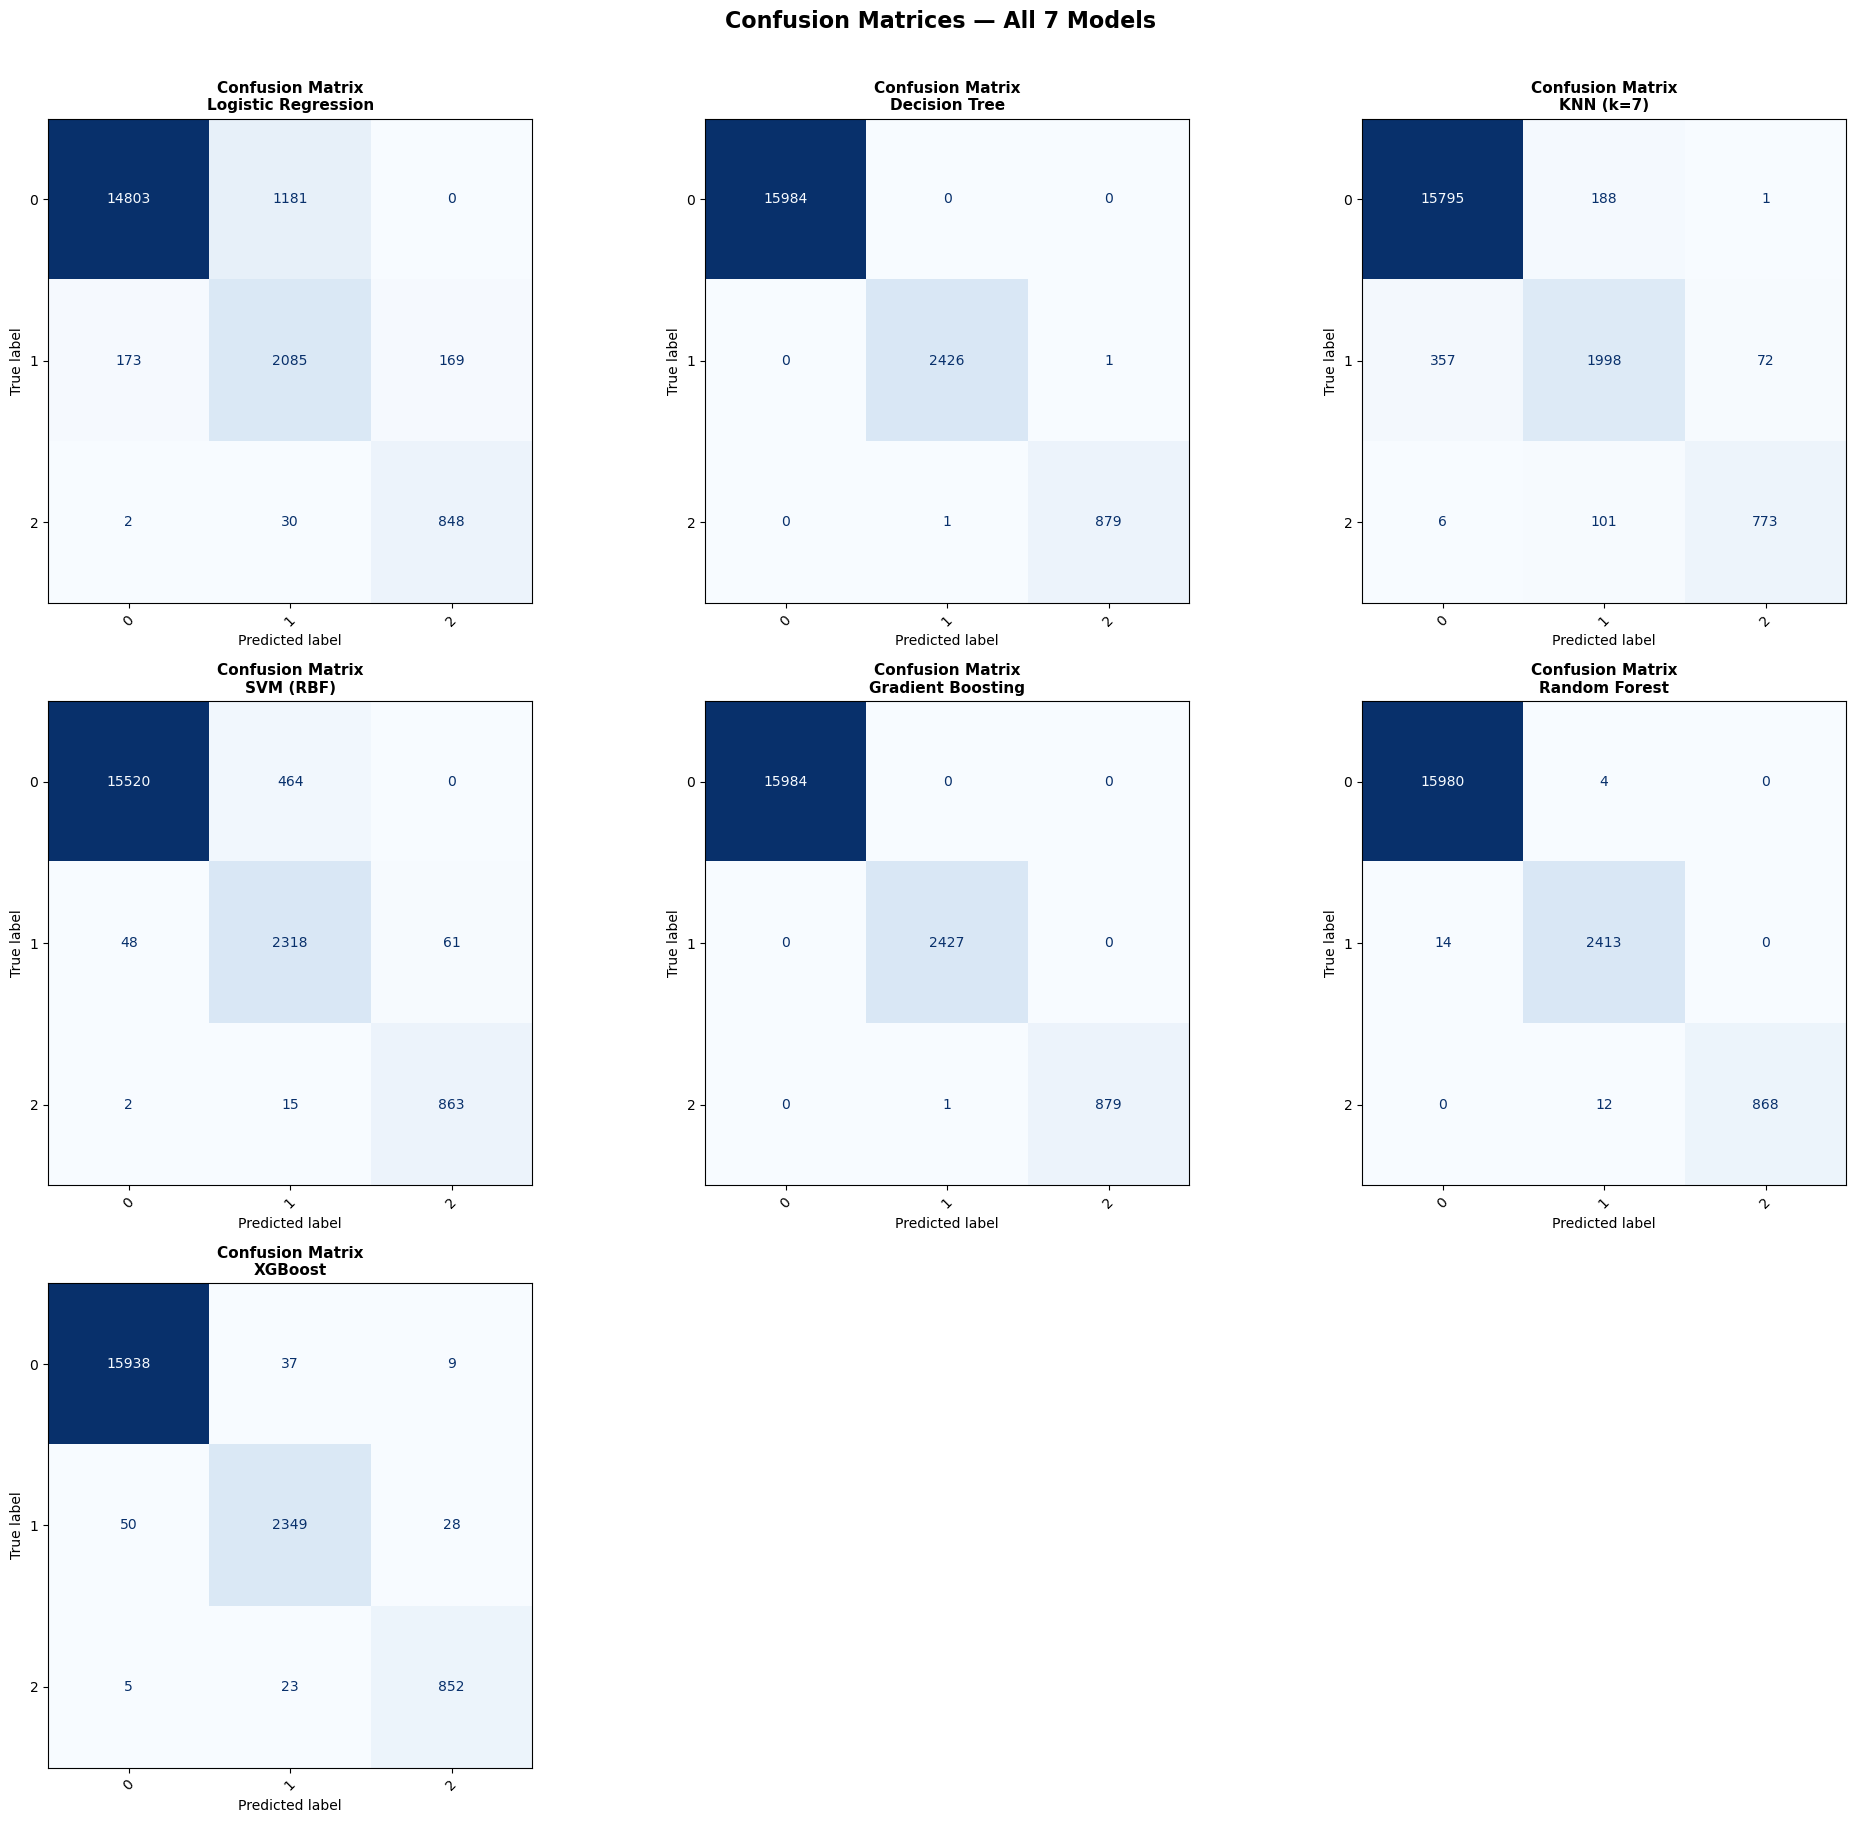

Saved → 01_confusion_matrices.png


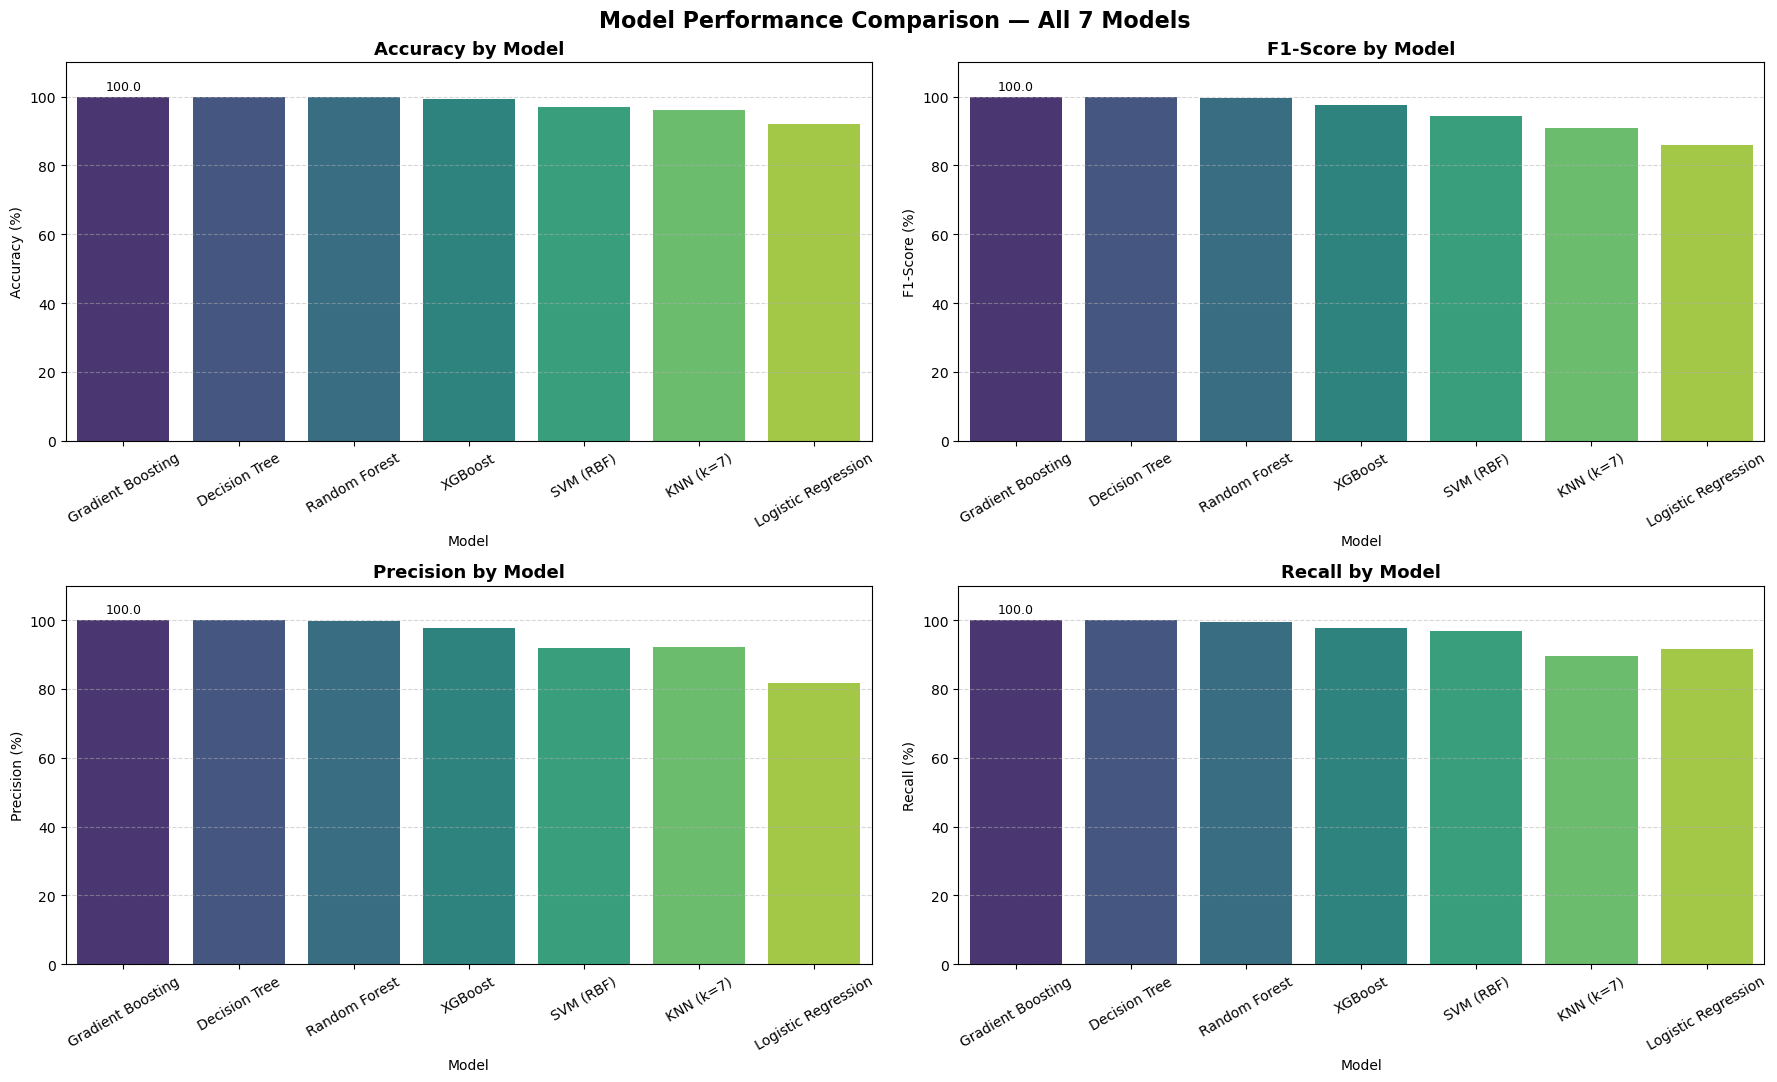

Saved → 02_model_comparison.png


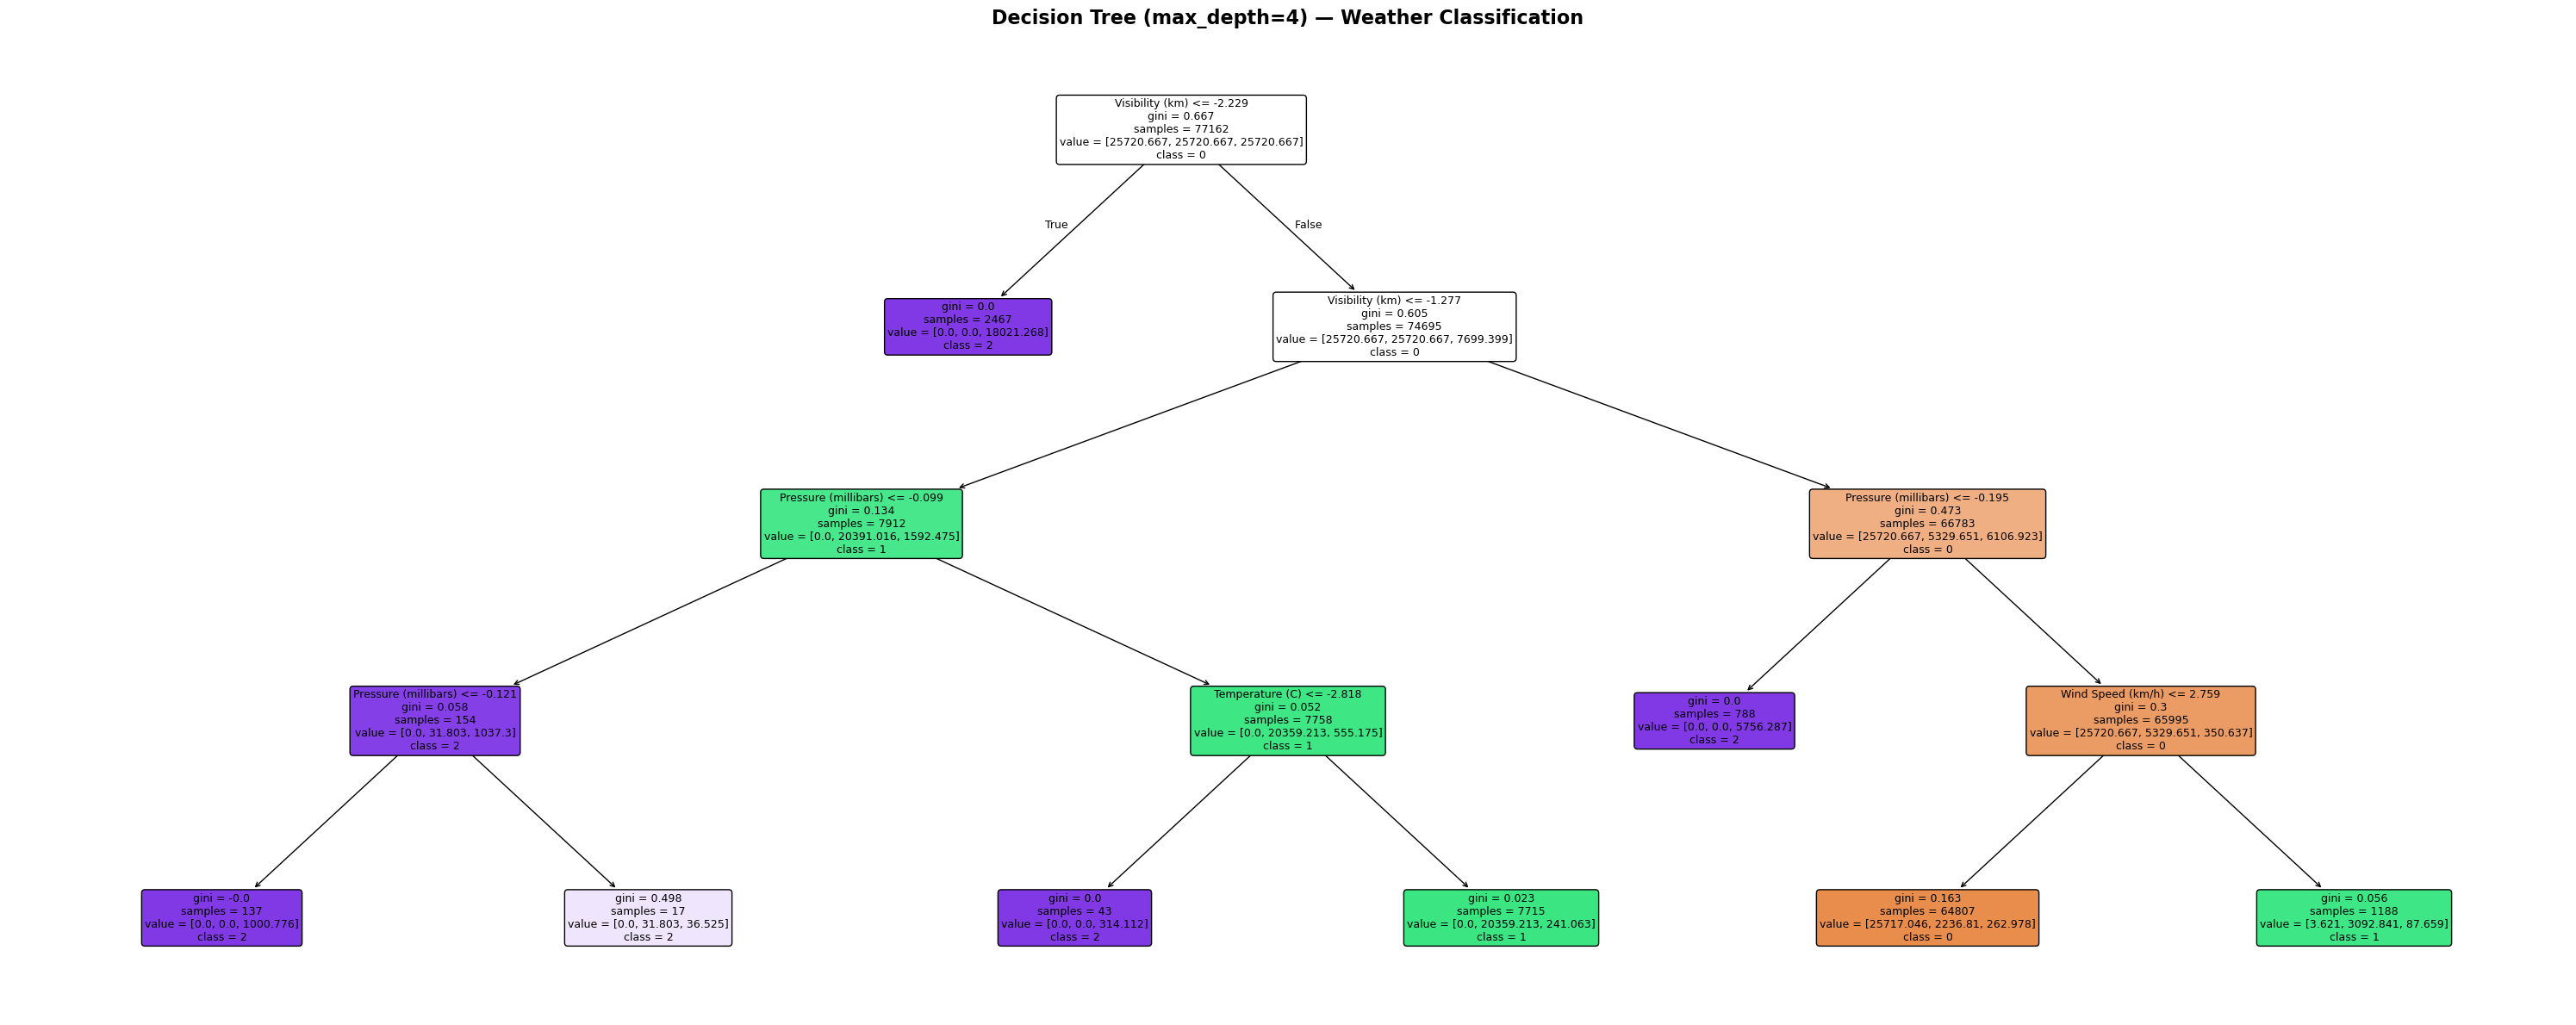

Saved → 03_decision_tree.png


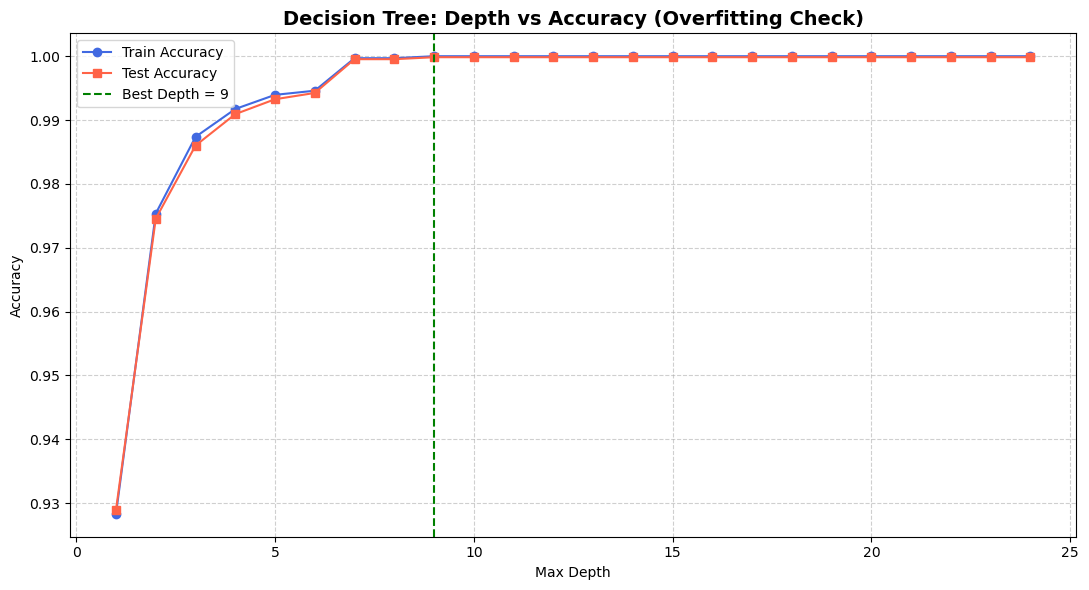

Saved → 04_tree_depth_vs_accuracy.png

Plotting decision boundaries (may take ~1 min for SVM & GB)...


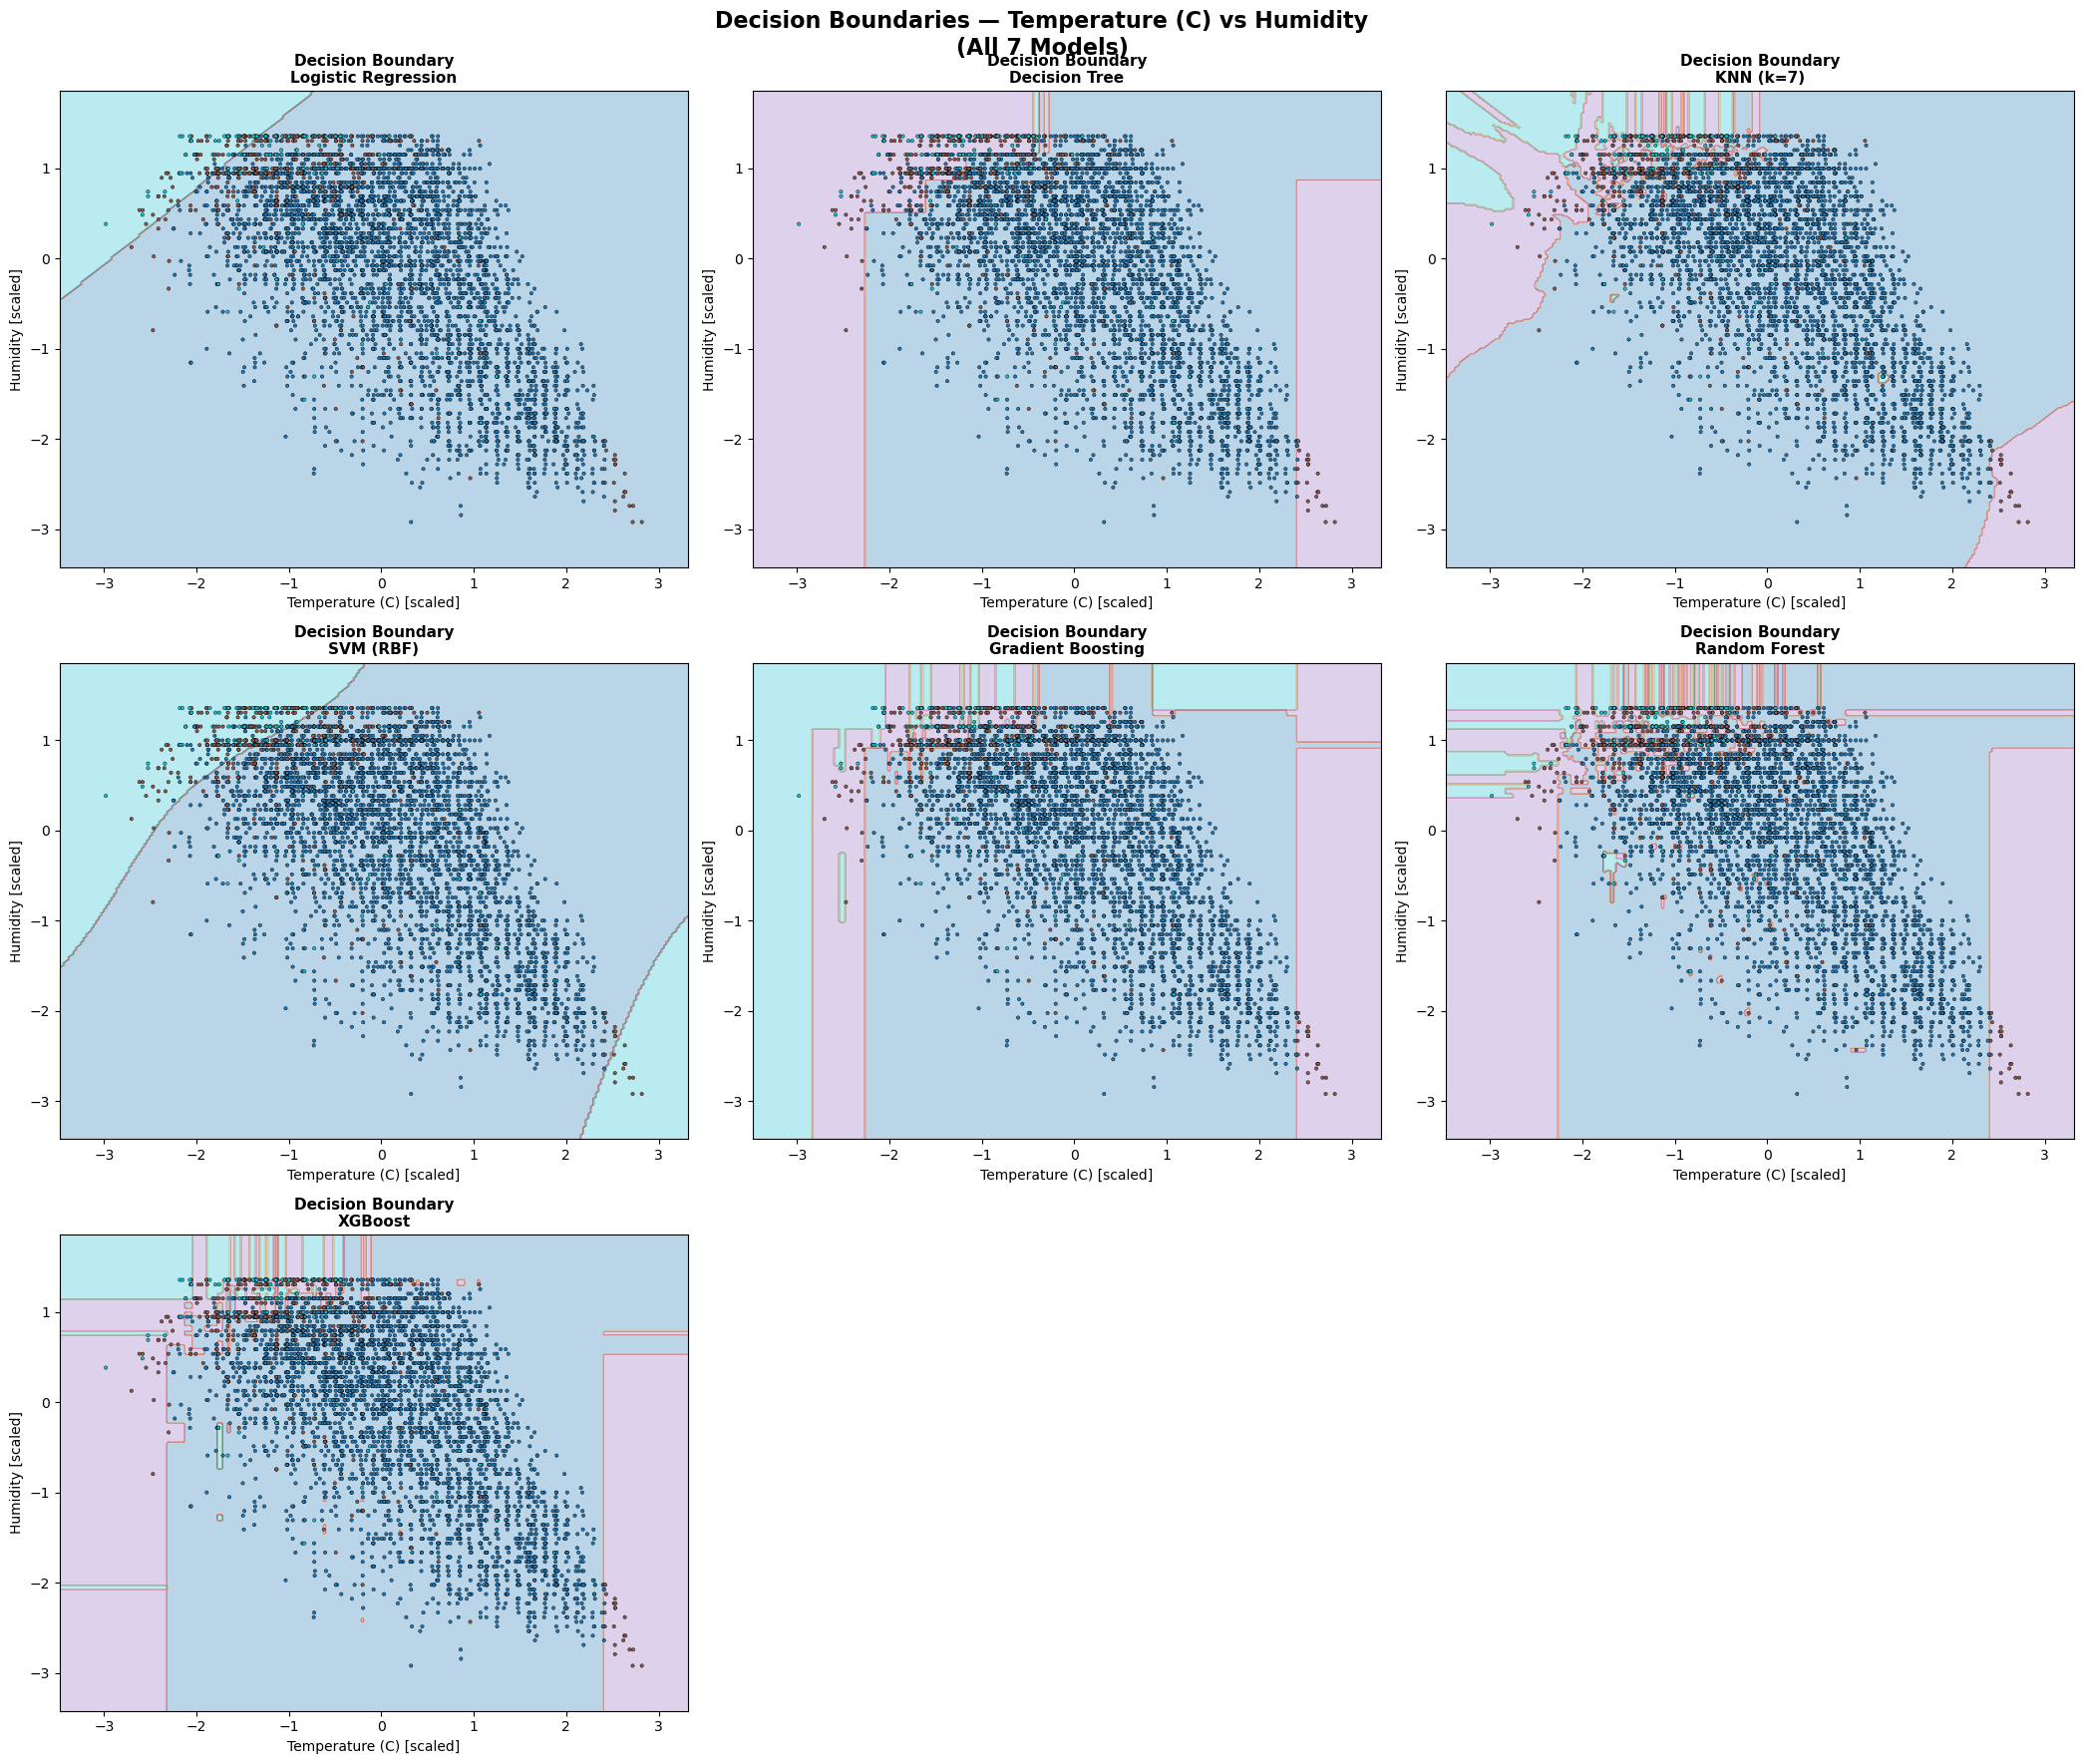

Saved → 05_decision_boundaries.png


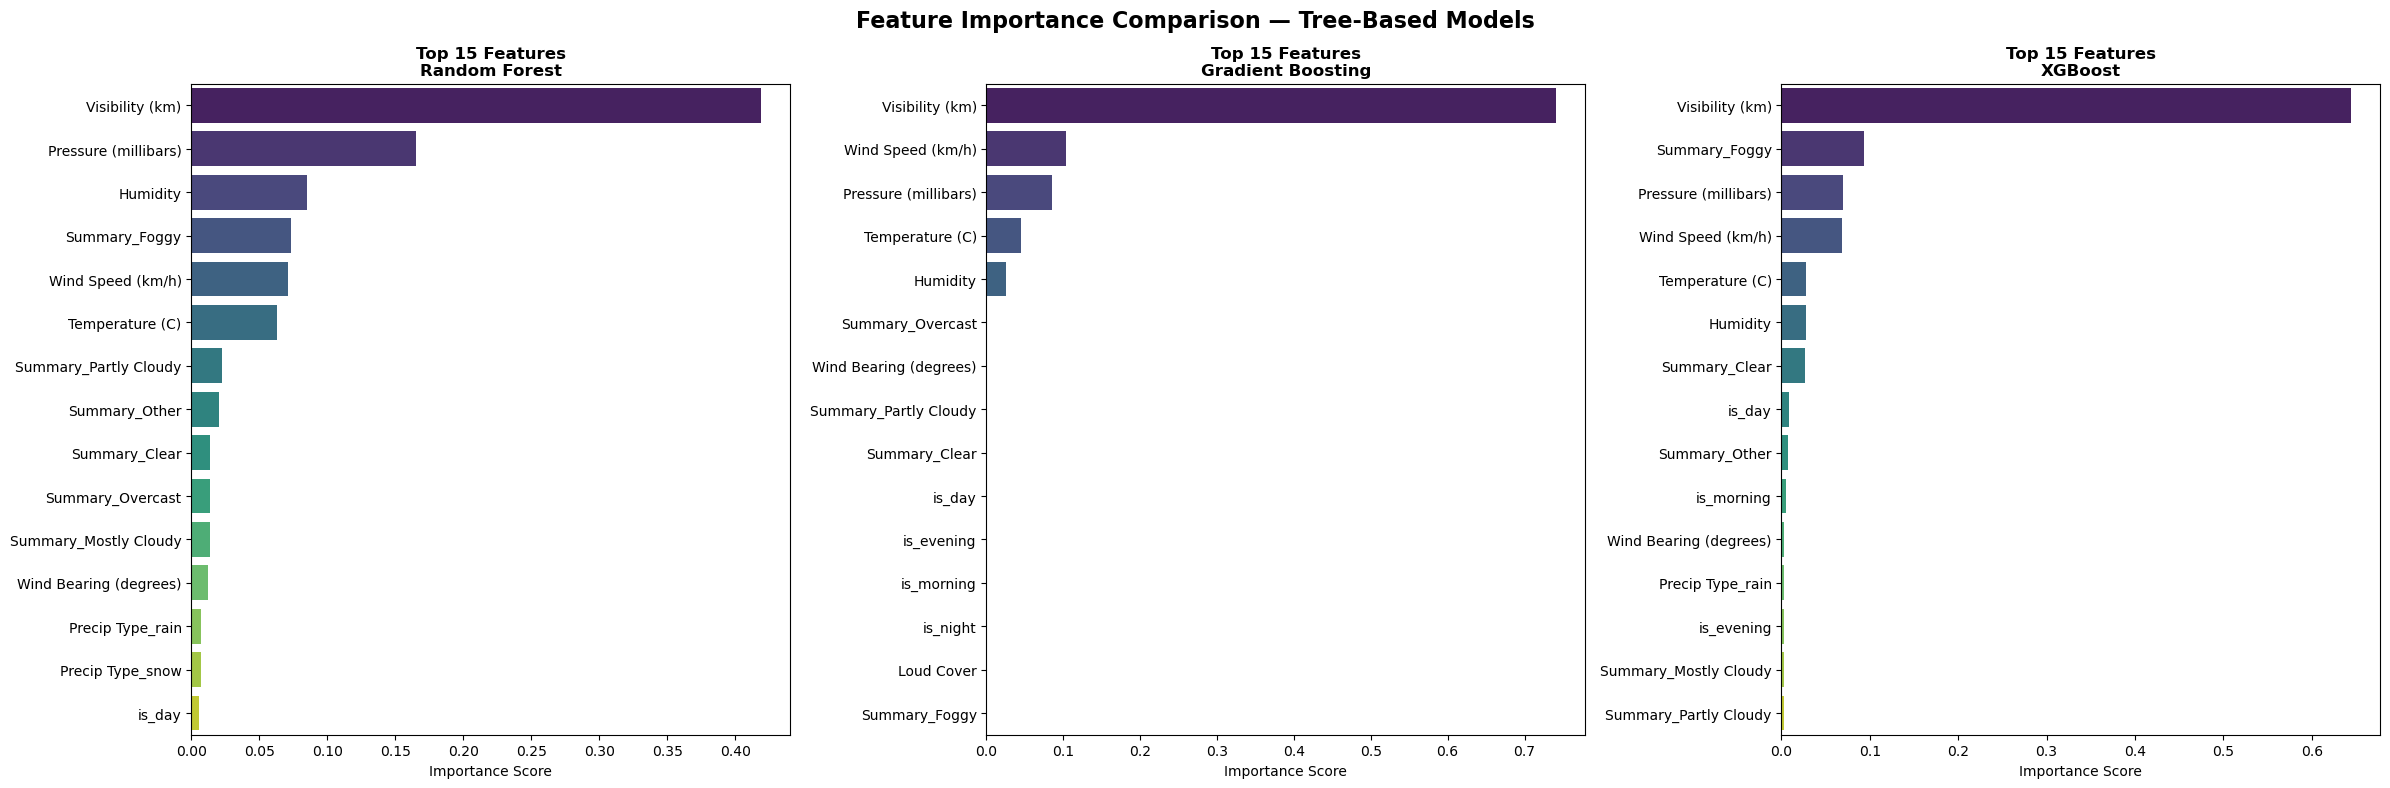

Saved → 06_feature_importance.png


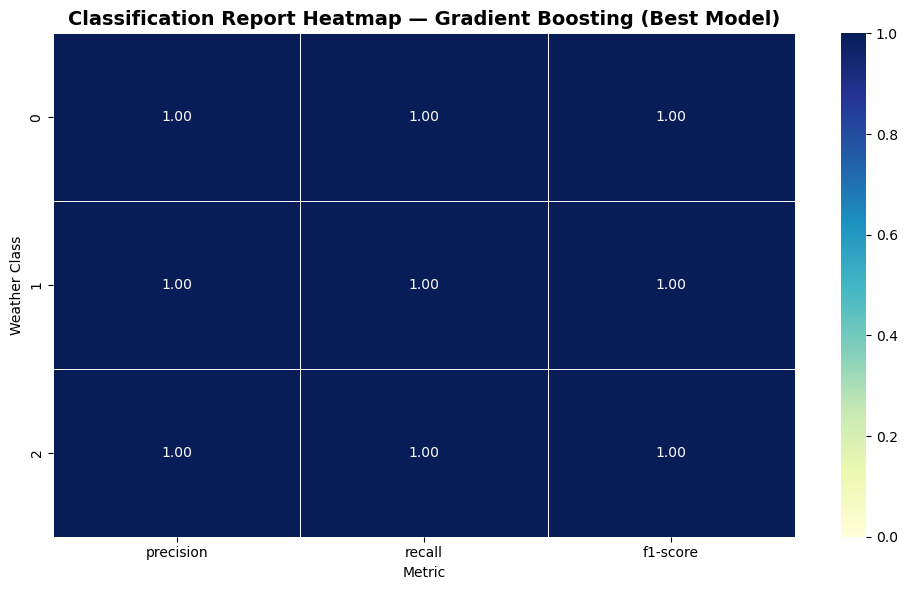

Saved → 07_classification_report_heatmap.png


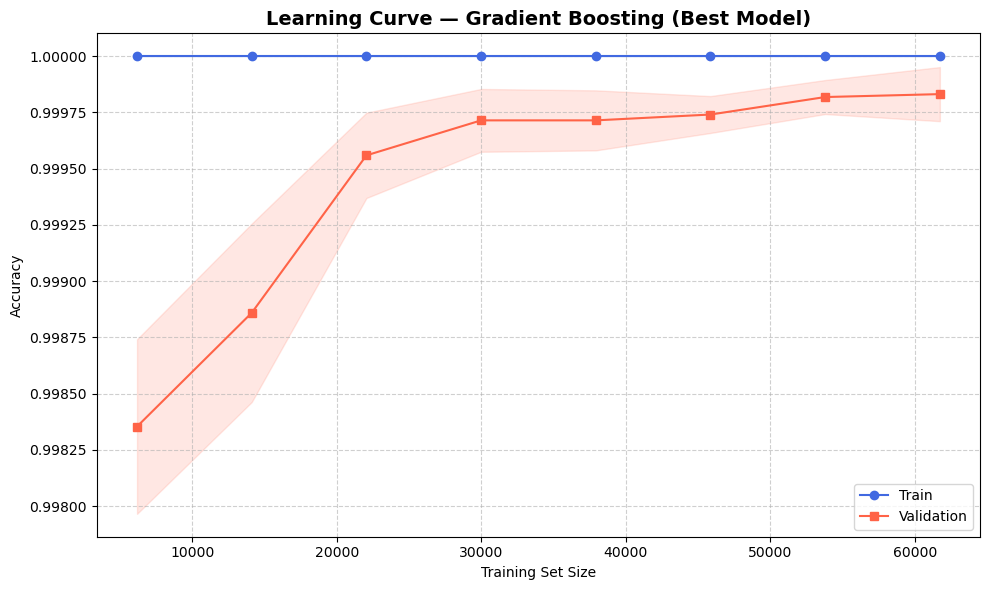

Saved → 08_learning_curve.png


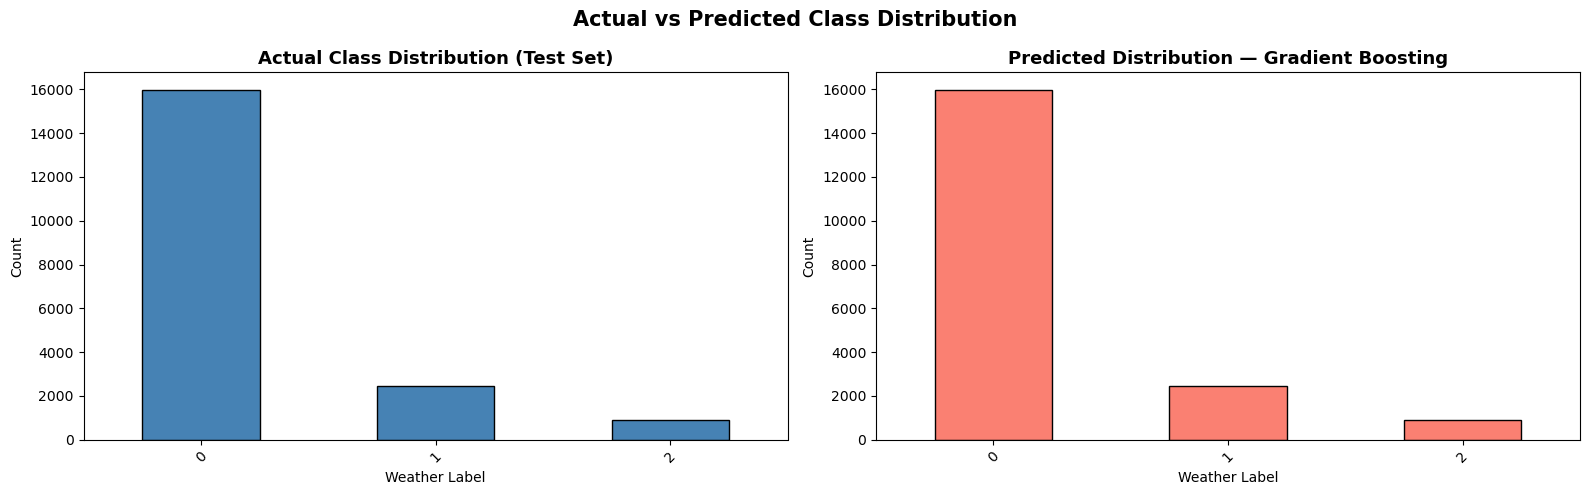

Saved → 09_actual_vs_predicted.png

✅  ALL 9 PLOTS GENERATED SUCCESSFULLY!

Files saved:
  01_confusion_matrices.png
  02_model_comparison.png
  03_decision_tree.png
  04_tree_depth_vs_accuracy.png
  05_decision_boundaries.png
  06_feature_importance.png
  07_classification_report_heatmap.png
  08_learning_curve.png
  09_actual_vs_predicted.png



In [51]:
# ============================================================
# COMPLETE MODEL VISUALIZATION CODE — ALL 7 MODELS
# Weather Classification - weatherHistory.csv
# Models: Logistic Regression, Decision Tree, KNN,
#         SVM (RBF), Gradient Boosting, Random Forest, XGBoost
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report,
                             accuracy_score, f1_score,
                             precision_score, recall_score)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# ============================================================
# PREPROCESSING  (df already loaded in your notebook)
# ============================================================

if 'Apparent Temperature (C)' in df.columns:
    df = df.drop(columns=['Apparent Temperature (C)'])

X = df.drop(columns=['Weather_Label', 'Weather_Label_Name', 'Formatted Date'], errors='ignore')
y = df['Weather_Label']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

class_names = sorted(y.unique())

# ============================================================
# ALL 7 MODELS  (matching your notebook exactly)
# ============================================================

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree":       DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "KNN (k=7)":           KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)":           SVC(kernel='rbf', class_weight='balanced'),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    "XGBoost":             XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42),
}

# ── Train all pipelines ──────────────────────────────────────
trained_pipelines = {}
y_preds = {}

print("🚀 Training all 7 models...\n")
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    y_preds[name] = pipe.predict(X_test)
    print(f"  ✅ {name} done")

print("\n✅ All models trained!\n")


# ============================================================
# PLOT 1 — CONFUSION MATRICES  (all 7 models)
# ============================================================

cols_grid, rows_grid = 3, 3          # 3×3 grid fits 7 plots comfortably
fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(20, 18))
axes = axes.flatten()

for idx, (name, pipe) in enumerate(trained_pipelines.items()):
    cm = confusion_matrix(y_test, y_preds[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=[str(c) for c in class_names])
    disp.plot(cmap='Blues', ax=axes[idx], colorbar=False)
    axes[idx].set_title(f"Confusion Matrix\n{name}", fontsize=11, fontweight='bold')
    axes[idx].tick_params(axis='x', rotation=45)

for j in range(len(models), len(axes)):   # hide unused subplot slots
    axes[j].set_visible(False)

plt.suptitle("Confusion Matrices — All 7 Models", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 01_confusion_matrices.png")


# ============================================================
# PLOT 2 — MODEL ACCURACY / METRICS COMPARISON  (all 7)
# ============================================================

metrics_results = []
for name, pipe in trained_pipelines.items():
    yp = y_preds[name]
    metrics_results.append({
        "Model":     name,
        "Accuracy":  accuracy_score(y_test, yp) * 100,
        "F1-Score":  f1_score(y_test, yp, average='macro') * 100,
        "Precision": precision_score(y_test, yp, average='macro') * 100,
        "Recall":    recall_score(y_test, yp, average='macro') * 100,
    })

metrics_df = pd.DataFrame(metrics_results).sort_values("Accuracy", ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, metric in zip(axes.flatten(), ["Accuracy", "F1-Score", "Precision", "Recall"]):
    bars = sns.barplot(x='Model', y=metric, data=metrics_df, palette='viridis', ax=ax)
    ax.set_title(f"{metric} by Model", fontsize=13, fontweight='bold')
    ax.set_ylabel(f"{metric} (%)")
    ax.set_ylim(0, 110)
    ax.tick_params(axis='x', rotation=30)
    ax.bar_label(ax.containers[0], fmt='%.1f', padding=3, fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Model Performance Comparison — All 7 Models", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 02_model_comparison.png")


# ============================================================
# PLOT 3 — DECISION TREE VISUALIZATION  (shallow, readable)
# ============================================================

dt_shallow = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
pipe_dt = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', dt_shallow)])
pipe_dt.fit(X_train, y_train)

ohe_feats = []
if cat_cols:
    ohe = pipe_dt.named_steps['preprocessor'].named_transformers_['cat']
    ohe_feats = list(ohe.get_feature_names_out(cat_cols))
all_feature_names = num_cols + ohe_feats

plt.figure(figsize=(30, 12))
plot_tree(
    pipe_dt.named_steps['classifier'],
    feature_names=all_feature_names,
    class_names=[str(c) for c in class_names],
    filled=True, rounded=True, fontsize=9, max_depth=4,
    impurity=True, proportion=False
)
plt.title("Decision Tree (max_depth=4) — Weather Classification",
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_decision_tree.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 03_decision_tree.png")


# ============================================================
# PLOT 4 — TREE DEPTH vs ACCURACY  (overfitting analysis)
# ============================================================

depths = range(1, 25)
train_accs, test_accs = [], []

for d in depths:
    pipe_d = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(max_depth=d, random_state=42))
    ])
    pipe_d.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, pipe_d.predict(X_train)))
    test_accs.append(accuracy_score(y_test,  pipe_d.predict(X_test)))

best_depth = list(depths)[np.argmax(test_accs)]

plt.figure(figsize=(11, 6))
plt.plot(depths, train_accs, 'o-', color='royalblue', label='Train Accuracy')
plt.plot(depths, test_accs,  's-', color='tomato',    label='Test Accuracy')
plt.axvline(x=best_depth, color='green', linestyle='--',
            label=f'Best Depth = {best_depth}')
plt.title("Decision Tree: Depth vs Accuracy (Overfitting Check)",
          fontsize=14, fontweight='bold')
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_tree_depth_vs_accuracy.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 04_tree_depth_vs_accuracy.png")


# ============================================================
# PLOT 5 — DECISION BOUNDARIES  (Temperature vs Humidity)
#          All 7 models using 2-feature scaled data
# ============================================================

scaler_2d = StandardScaler()
X_2d = scaler_2d.fit_transform(df[['Temperature (C)', 'Humidity']].values)
y_2d = df['Weather_Label'].values

# Sample 5000 rows — decision boundary is expensive on 96k rows
np.random.seed(42)
idx = np.random.choice(len(X_2d), size=5000, replace=False)
X_2d_s, y_2d_s = X_2d[idx], y_2d[idx]

boundary_models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN (k=7)":           KNeighborsClassifier(n_neighbors=7),
    "SVM (RBF)":           SVC(kernel='rbf'),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=50, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=50, random_state=42),
    "XGBoost":             XGBClassifier(n_estimators=50, eval_metric='mlogloss',
                                         use_label_encoder=False, random_state=42),
}

def plot_decision_boundary(model, X_2d, y_2d, title, ax):
    x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
    y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                         np.linspace(y_min, y_max, 250))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap='tab10',
               edgecolor='k', s=6, linewidths=0.3)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("Temperature (C) [scaled]")
    ax.set_ylabel("Humidity [scaled]")

fig, axes = plt.subplots(3, 3, figsize=(21, 18))
axes = axes.flatten()

print("\nPlotting decision boundaries (may take ~1 min for SVM & GB)...")
for i, (name, mdl) in enumerate(boundary_models.items()):
    mdl.fit(X_2d_s, y_2d_s)
    plot_decision_boundary(mdl, X_2d_s, y_2d_s, f"Decision Boundary\n{name}", axes[i])

for j in range(len(boundary_models), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Decision Boundaries — Temperature (C) vs Humidity\n(All 7 Models)",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_decision_boundaries.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 05_decision_boundaries.png")


# ============================================================
# PLOT 6 — FEATURE IMPORTANCE
#          Random Forest + Gradient Boosting + XGBoost
# ============================================================

tree_models_for_importance = {
    "Random Forest":     trained_pipelines["Random Forest"],
    "Gradient Boosting": trained_pipelines["Gradient Boosting"],
    "XGBoost":           trained_pipelines["XGBoost"],
}

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, (name, pipe) in zip(axes, tree_models_for_importance.items()):
    importances = pipe.named_steps['classifier'].feature_importances_

    ohe_f = []
    if cat_cols:
        ohe_t = pipe.named_steps['preprocessor'].named_transformers_['cat']
        ohe_f = list(ohe_t.get_feature_names_out(cat_cols))

    feat_df = pd.DataFrame({
        'Feature':    num_cols + ohe_f,
        'Importance': importances
    }).sort_values('Importance', ascending=False).head(15)

    sns.barplot(x='Importance', y='Feature', data=feat_df, palette='viridis', ax=ax)
    ax.set_title(f"Top 15 Features\n{name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Importance Score")
    ax.set_ylabel("")

plt.suptitle("Feature Importance Comparison — Tree-Based Models",
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 06_feature_importance.png")


# ============================================================
# PLOT 7 — CLASSIFICATION REPORT HEATMAP  (best model)
# ============================================================

best_name = metrics_df.iloc[0]['Model']
best_pred = y_preds[best_name]

report_dict = classification_report(
    y_test, best_pred,
    target_names=[str(c) for c in class_names],
    output_dict=True
)
report_df = (pd.DataFrame(report_dict).T
               .drop(index=['accuracy', 'macro avg', 'weighted avg'], errors='ignore')
               [['precision', 'recall', 'f1-score']]
               .astype(float))

plt.figure(figsize=(10, 6))
sns.heatmap(report_df, annot=True, fmt=".2f", cmap='YlGnBu',
            linewidths=0.5, vmin=0, vmax=1)
plt.title(f"Classification Report Heatmap — {best_name} (Best Model)",
          fontsize=14, fontweight='bold')
plt.xlabel("Metric")
plt.ylabel("Weather Class")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_classification_report_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 07_classification_report_heatmap.png")


# ============================================================
# PLOT 8 — LEARNING CURVE  (best model — overfitting check)
# ============================================================

train_sizes, train_scores, val_scores = learning_curve(
    trained_pipelines[best_name], X_train, y_train,
    cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', color='royalblue', label='Train')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1),
                 alpha=0.15, color='royalblue')
plt.plot(train_sizes, val_scores.mean(axis=1), 's-', color='tomato', label='Validation')
plt.fill_between(train_sizes,
                 val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1),
                 alpha=0.15, color='tomato')
plt.title(f"Learning Curve — {best_name} (Best Model)",
          fontsize=14, fontweight='bold')
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_learning_curve.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 08_learning_curve.png")


# ============================================================
# PLOT 9 — ACTUAL vs PREDICTED DISTRIBUTION  (best model)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

pd.Series(y_test).value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title("Actual Class Distribution (Test Set)",
                  fontsize=13, fontweight='bold')
axes[0].set_xlabel("Weather Label")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=45)

pd.Series(best_pred).value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='salmon', edgecolor='black')
axes[1].set_title(f"Predicted Distribution — {best_name}",
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel("Weather Label")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle("Actual vs Predicted Class Distribution",
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_actual_vs_predicted.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved → 09_actual_vs_predicted.png")


# ============================================================
print("\n" + "="*55)
print("✅  ALL 9 PLOTS GENERATED SUCCESSFULLY!")
print("="*55)
print("""
Files saved:
  01_confusion_matrices.png
  02_model_comparison.png
  03_decision_tree.png
  04_tree_depth_vs_accuracy.png
  05_decision_boundaries.png
  06_feature_importance.png
  07_classification_report_heatmap.png
  08_learning_curve.png
  09_actual_vs_predicted.png
""")